In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
import requests

url = "https://data.sec.gov/api/xbrl/companyfacts/CIK0001048286.json"

headers = {
    "User-Agent": "Hotel Audit Project your-email@example.com"
}

response = requests.get(url, headers=headers)

data = response.json()

In [3]:
us_gaap = data["facts"]["us-gaap"]

In [4]:
from datetime import date

def get_annual_facts(us_gaap, concept_name, start_year, end_year):
    """
    Extract one annual observation per fiscal year from SEC Company Facts.

    Handles:
    - instant facts: balance-sheet items
    - duration facts: income-statement items
    """

    facts = us_gaap[concept_name]["units"]["USD"]

    candidates = [
        item
        for item in facts
        if (
            item.get("fy") is not None
            and start_year <= item["fy"] <= end_year
            and item.get("form") == "10-K"
        )
    ]

    annual_facts = []

    for fy in range(start_year, end_year + 1):

        year_facts = [
            item
            for item in candidates
            if item["fy"] == fy
        ]

        if not year_facts:
            continue

        duration_facts = [
            item for item in year_facts
            if "start" in item
        ]

        instant_facts = [
            item for item in year_facts
            if "start" not in item
        ]

        if duration_facts:

            annual_candidates = []

            for item in duration_facts:
                start = date.fromisoformat(item["start"])
                end = date.fromisoformat(item["end"])

                duration_days = (end - start).days

                if 300 <= duration_days <= 400:
                    annual_candidates.append(item)

            if not annual_candidates:
                continue

            annual = max(
                annual_candidates,
                key=lambda item: item["end"]
            )

        else:
            instant_candidates = [
                item for item in year_facts
                if "start" not in item
            ]

            if not instant_candidates:
                continue

            annual = max(
                instant_candidates,
                key=lambda item: item["end"]
            )

        annual_facts.append(annual)

    return annual_facts

In [5]:
revenue = get_annual_facts(
    us_gaap,
    "Revenues",
    2015,
    2025
)

receivables = get_annual_facts(
    us_gaap,
    "AccountsNotesAndLoansReceivableNetCurrent",
    2015,
    2025
)

In [6]:
df = pd.DataFrame({
    "year": [item["fy"] for item in revenue],
    "revenue": [item["val"] for item in revenue],
    "receivables": [item["val"] for item in receivables],
})

In [7]:
df["revenue_growth"] = df["revenue"].pct_change()
df["receivables_growth"] = df["receivables"].pct_change()

In [8]:
df["divergence"] = (
    df["revenue_growth"] -
    df["receivables_growth"]
)
df["abs_divergence"] = df["divergence"].abs()

In [9]:
df["divergence"].describe()

count    10.000000
mean     -0.019431
std       0.192038
min      -0.358201
25%      -0.151596
50%       0.015183
75%       0.146468
max       0.201923
Name: divergence, dtype: float64

In [10]:
df["period"] = pd.cut(
    df["year"],
    bins=[2015, 2019, 2020, 2025],
    labels=["Pre-2020", "2020", "Post-2020"]
)
df.groupby("period", observed=True)["abs_divergence"].agg(
    ["mean", "std", "count"]
)

,mean,std,count
period,,,
Pre-2020,0.200435,0.108105,4
2020,0.234152,NaN,1
Post-2020,0.101757,0.091278,5


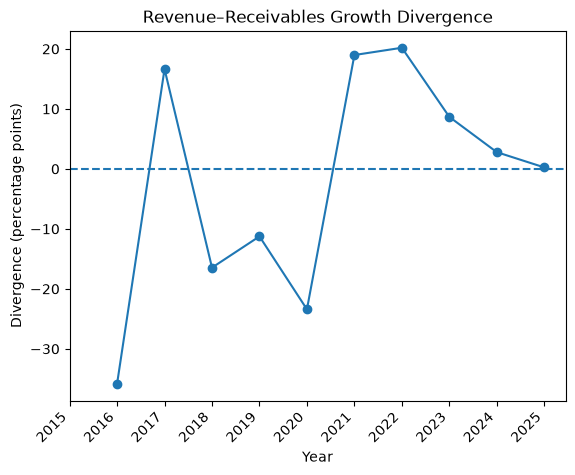

In [11]:
plt.plot(
    df["year"],
    df["divergence"] * 100,
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.title("Revenue–Receivables Growth Divergence")
plt.xlabel("Year")
plt.ylabel("Divergence (percentage points)")

plt.xticks(
    df["year"],
    rotation=45,
    ha="right"
)

plt.show()

In [12]:
[c for c in us_gaap if "OperatingActivities" in c and "Cash" in c]

['NetCashProvidedByUsedInOperatingActivities',
 'OtherOperatingActivitiesCashFlowStatement']

In [13]:
[c for c in us_gaap if "OperatingActivities" in c and "Cash" in c]

['NetCashProvidedByUsedInOperatingActivities',
 'OtherOperatingActivitiesCashFlowStatement']

In [14]:
for concept in [
    "NetCashProvidedByUsedInOperatingActivities",
    "OtherOperatingActivitiesCashFlowStatement"
]:
    print("CONCEPT:", concept)
    print("LABEL:", us_gaap[concept]["label"])
    print("DESCRIPTION:", us_gaap[concept].get("description"))
    print("UNITS:", us_gaap[concept]["units"].keys())
    print("-" * 80)

CONCEPT: NetCashProvidedByUsedInOperatingActivities
LABEL: Net Cash Provided by (Used in) Operating Activities
DESCRIPTION: Amount of cash inflow (outflow) from operating activities, including discontinued operations. Operating activity cash flows include transactions, adjustments, and changes in value not defined as investing or financing activities.
UNITS: dict_keys(['USD'])
--------------------------------------------------------------------------------
CONCEPT: OtherOperatingActivitiesCashFlowStatement
LABEL: Other Operating Activities, Cash Flow Statement
DESCRIPTION: Other cash or noncash adjustments to reconcile net income to cash provided by (used in) operating activities that are not separately disclosed in the statement of cash flows (for example, cash received or cash paid during the current period for miscellaneous operating activities, net change during the reporting period in other assets or other liabilities).
UNITS: dict_keys(['USD'])
-----------------------------------

In [15]:
concept = "NetCashProvidedByUsedInOperatingActivities"

print(us_gaap[concept]["label"])
print(us_gaap[concept]["description"])
print(us_gaap[concept]["units"].keys())

Net Cash Provided by (Used in) Operating Activities
Amount of cash inflow (outflow) from operating activities, including discontinued operations. Operating activity cash flows include transactions, adjustments, and changes in value not defined as investing or financing activities.
dict_keys(['USD'])


In [16]:
concept = "NetCashProvidedByUsedInOperatingActivities"

print("LABEL:")
print(us_gaap[concept]["label"])

print("\nDESCRIPTION:")
print(us_gaap[concept]["description"])

print("\nUNITS:")
print(us_gaap[concept]["units"].keys())

LABEL:
Net Cash Provided by (Used in) Operating Activities

DESCRIPTION:
Amount of cash inflow (outflow) from operating activities, including discontinued operations. Operating activity cash flows include transactions, adjustments, and changes in value not defined as investing or financing activities.

UNITS:
dict_keys(['USD'])


In [17]:
facts = us_gaap[concept]["units"]["USD"]

for item in facts[:5]:
    print(item)
    print("-" * 80)

{'start': '2006-12-30', 'end': '2007-12-28', 'val': 778000000, 'accn': '0001193125-10-030603', 'fy': 2009, 'fp': 'FY', 'form': '10-K', 'filed': '2010-02-12', 'frame': 'CY2007'}
--------------------------------------------------------------------------------
{'start': '2007-12-29', 'end': '2008-06-13', 'val': 357000000, 'accn': '0001193125-09-150935', 'fy': 2009, 'fp': 'Q2', 'form': '10-Q', 'filed': '2009-07-17'}
--------------------------------------------------------------------------------
{'start': '2007-12-29', 'end': '2008-09-05', 'val': 555000000, 'accn': '0001193125-09-206036', 'fy': 2009, 'fp': 'Q3', 'form': '10-Q', 'filed': '2009-10-09'}
--------------------------------------------------------------------------------
{'start': '2007-12-29', 'end': '2009-01-02', 'val': 641000000, 'accn': '0001193125-10-030603', 'fy': 2009, 'fp': 'FY', 'form': '10-K', 'filed': '2010-02-12'}
--------------------------------------------------------------------------------
{'start': '2007-12-29', '

In [18]:
cash_flow_operations = get_annual_facts(
    us_gaap,
    "NetCashProvidedByUsedInOperatingActivities",
    2015,
    2025
)
len(cash_flow_operations)

11

In [19]:
for item in cash_flow_operations:
    print(
        item["fy"],
        item["val"],
        item["start"],
        item["end"]
    )

2015 1430000000 2015-01-01 2015-12-31
2016 1582000000 2016-01-01 2016-12-31
2017 2436000000 2017-01-01 2017-12-31
2018 2357000000 2018-01-01 2018-12-31
2019 1685000000 2019-01-01 2019-12-31
2020 1639000000 2020-01-01 2020-12-31
2021 1177000000 2021-01-01 2021-12-31
2022 2363000000 2022-01-01 2022-12-31
2023 3170000000 2023-01-01 2023-12-31
2024 2749000000 2024-01-01 2024-12-31
2025 3212000000 2025-01-01 2025-12-31


In [20]:
df["operating_cash_flow"] = [
    item["val"] for item in cash_flow_operations
]

In [21]:
df

,year,revenue,receivables,revenue_growth,receivables_growth,divergence,abs_divergence,period,operating_cash_flow
0,2015,14486000000,1103000000,NaN,NaN,NaN,NaN,NaN,1430000000
1,2016,17072000000,1695000000,0.178517,0.536718,-0.358201,0.358201,Pre-2020,1582000000
2,2017,22894000000,1991000000,0.341026,0.174631,0.166395,0.166395,Pre-2020,2436000000
3,2018,20758000000,2133000000,-0.093300,0.071321,-0.164620,0.164620,Pre-2020,2357000000
4,2019,20972000000,2395000000,0.010309,0.122832,-0.112522,0.112522,Pre-2020,1685000000
5,2020,10571000000,1768000000,-0.495947,-0.261795,-0.234152,0.234152,2020,1639000000
6,2021,13857000000,1982000000,0.310850,0.121041,0.189810,0.189810,Post-2020,1177000000
7,2022,20773000000,2571000000,0.499098,0.297175,0.201923,0.201923,Post-2020,2363000000
8,2023,23713000000,2712000000,0.141530,0.054842,0.086687,0.086687,Post-2020,3170000000
9,2024,25100000000,2795000000,0.058491,0.030605,0.027886,0.027886,Post-2020,2749000000


In [22]:
df_check = df[
    ["year", "revenue", "receivables", "operating_cash_flow"]
].copy()

print(
    df_check.to_string(
        formatters={
            "revenue": "{:,.0f}".format,
            "receivables": "{:,.0f}".format,
            "operating_cash_flow": "{:,.0f}".format,
        },
        index=False
    )
)

 year        revenue   receivables operating_cash_flow
 2015 14,486,000,000 1,103,000,000       1,430,000,000
 2016 17,072,000,000 1,695,000,000       1,582,000,000
 2017 22,894,000,000 1,991,000,000       2,436,000,000
 2018 20,758,000,000 2,133,000,000       2,357,000,000
 2019 20,972,000,000 2,395,000,000       1,685,000,000
 2020 10,571,000,000 1,768,000,000       1,639,000,000
 2021 13,857,000,000 1,982,000,000       1,177,000,000
 2022 20,773,000,000 2,571,000,000       2,363,000,000
 2023 23,713,000,000 2,712,000,000       3,170,000,000
 2024 25,100,000,000 2,795,000,000       2,749,000,000
 2025 26,186,000,000 2,909,000,000       3,212,000,000


In [23]:
df["operating_cash_flow_growth"] = (
    df["operating_cash_flow"].pct_change()
)



In [24]:
pd.reset_option("display.float_format")

In [25]:
df[["year", "operating_cash_flow_growth"]]

,year,operating_cash_flow_growth
0,2015,NaN
1,2016,0.106294
2,2017,0.539823
3,2018,-0.032430
4,2019,-0.285108
5,2020,-0.027300
6,2021,-0.281879
7,2022,1.007647
8,2023,0.341515
9,2024,-0.132808


In [26]:
df["cfo_divergence"] = (
    df["revenue_growth"] -
    df["operating_cash_flow_growth"]
)
df["abs_cfo_divergence"] = df["cfo_divergence"].abs()
df[
    ["year",
     "revenue_growth",
     "operating_cash_flow_growth",
     "cfo_divergence"]
]

,year,revenue_growth,operating_cash_flow_growth,cfo_divergence
0,2015,NaN,NaN,NaN
1,2016,0.178517,0.106294,0.072223
2,2017,0.341026,0.539823,-0.198797
3,2018,-0.093300,-0.032430,-0.060869
4,2019,0.010309,-0.285108,0.295417
5,2020,-0.495947,-0.027300,-0.468647
6,2021,0.310850,-0.281879,0.592730
7,2022,0.499098,1.007647,-0.508549
8,2023,0.141530,0.341515,-0.199985
9,2024,0.058491,-0.132808,0.191299


In [27]:
df["cfo_divergence"].describe()


count    10.000000
mean     -0.041034
std       0.340051
min      -0.508549
25%      -0.199688
50%      -0.093014
75%       0.161530
max       0.592730
Name: cfo_divergence, dtype: float64

In [28]:
df["abs_cfo_divergence"].describe()

count    10.000000
mean      0.271367
std       0.188899
min       0.060869
25%       0.141693
50%       0.199391
75%       0.425340
max       0.592730
Name: abs_cfo_divergence, dtype: float64

In [29]:
q1 = df["cfo_divergence"].quantile(0.25)
q3 = df["cfo_divergence"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

q1, q3, iqr, lower_bound, upper_bound

(np.float64(-0.1996880563404162),
 np.float64(0.16152989117205163),
 np.float64(0.36121794751246783),
 np.float64(-0.7415149776091179),
 np.float64(0.7033568124407533))

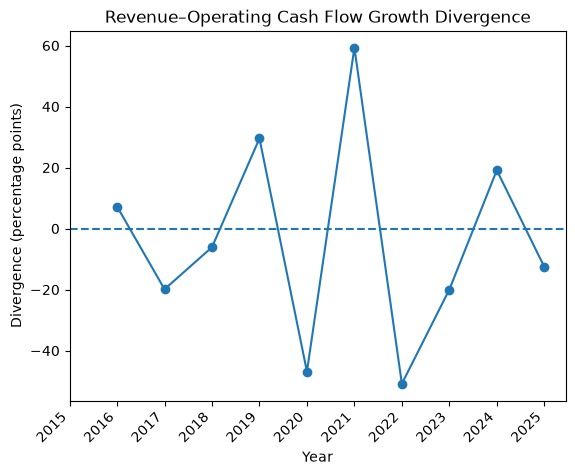

In [30]:
plt.plot(
    df["year"],
    df["cfo_divergence"] * 100,
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.title("Revenue–Operating Cash Flow Growth Divergence")
plt.xlabel("Year")
plt.ylabel("Divergence (percentage points)")

plt.xticks(
    df["year"],
    rotation=45,
    ha="right"
)

plt.show()

In [31]:
[c for c in us_gaap if "OperatingActivities" in c]

['NetCashProvidedByUsedInOperatingActivities',
 'OtherOperatingActivitiesCashFlowStatement']

In [32]:
[c for c in us_gaap if "Receivable" in c]

['AccountsAndFinancingReceivableAllowanceForCreditLoss',
 'AccountsNotesAndLoansReceivableNetCurrent',
 'AllowanceForDoubtfulAccountsReceivableCurrent',
 'AllowanceForNotesReceivable',
 'FinancingReceivableAllowanceForCreditLosses',
 'FinancingReceivableAllowanceForCreditLossesPeriodIncreaseDecrease',
 'FinancingReceivableAllowanceForCreditLossesProvisions',
 'FinancingReceivableAllowanceForCreditLossesWriteOffs',
 'FinancingReceivableRecordedInvestmentPastDue',
 'ImpairedFinancingReceivableAverageRecordedInvestment',
 'ImpairedFinancingReceivableRecordedInvestment',
 'ImpairedFinancingReceivableWithNoRelatedAllowanceRecordedInvestment',
 'NotesAndLoansReceivableNetCurrent',
 'NotesAndLoansReceivableNetNoncurrent',
 'NotesReceivableNet',
 'OtherReceivables',
 'ProceedsFromSaleAndCollectionOfLoansReceivable',
 'ProceedsFromSaleAndCollectionOfNotesReceivable',
 'ReceivableWithImputedInterestDiscount',
 'AllowanceForDoubtfulAccountsReceivable']

In [33]:
[c for c in us_gaap if "IncreaseDecrease" in c]

['CashAndCashEquivalentsPeriodIncreaseDecrease',
 'CashCashEquivalentsRestrictedCashAndRestrictedCashEquivalentsPeriodIncreaseDecreaseIncludingExchangeRateEffect',
 'FinancingReceivableAllowanceForCreditLossesPeriodIncreaseDecrease',
 'IncreaseDecreaseInContractWithCustomerLiability',
 'IncreaseDecreaseInCustomerLoyaltyProgramLiability',
 'IncreaseDecreaseInOtherOperatingCapitalNet',
 'OtherComprehensiveIncomeDerivativesQualifyingAsHedgesNetOfTaxPeriodIncreaseDecrease',
 'OtherComprehensiveIncomeForeignCurrencyTransactionAndTranslationAdjustmentBeforeTaxPeriodIncreaseDecrease',
 'OtherComprehensiveIncomeForeignCurrencyTransactionAndTranslationAdjustmentNetOfTaxPeriodIncreaseDecrease',
 'OtherComprehensiveIncomeLossNetOfTaxPeriodIncreaseDecrease',
 'UnrecognizedTaxBenefitsPeriodIncreaseDecrease']

In [34]:
concept = "IncreaseDecreaseInOtherOperatingCapitalNet"

print("LABEL:")
print(us_gaap[concept]["label"])

print("\nDESCRIPTION:")
print(us_gaap[concept]["description"])

print("\nUNITS:")
print(us_gaap[concept]["units"].keys())

LABEL:
Increase (Decrease) in Other Operating Assets and Liabilities, Net

DESCRIPTION:
Amount of increase (decrease) in operating assets after deduction of operating liabilities classified as other.

UNITS:
dict_keys(['USD'])


In [35]:
facts = us_gaap[concept]["units"]["USD"]

for item in facts[:10]:
    print(item)
    print("-" * 80)

{'start': '2009-01-03', 'end': '2010-01-01', 'val': -106000000, 'accn': '0001445305-12-000342', 'fy': 2011, 'fp': 'FY', 'form': '10-K', 'filed': '2012-02-16', 'frame': 'CY2009'}
--------------------------------------------------------------------------------
{'start': '2010-01-02', 'end': '2010-09-10', 'val': -177000000, 'accn': '0001445305-11-002911', 'fy': 2011, 'fp': 'Q3', 'form': '10-Q', 'filed': '2011-10-07'}
--------------------------------------------------------------------------------
{'start': '2010-01-02', 'end': '2010-12-31', 'val': -120000000, 'accn': '0001445305-12-000342', 'fy': 2011, 'fp': 'FY', 'form': '10-K', 'filed': '2012-02-16'}
--------------------------------------------------------------------------------
{'start': '2010-01-02', 'end': '2010-12-31', 'val': -120000000, 'accn': '0001445305-13-000255', 'fy': 2012, 'fp': 'FY', 'form': '10-K', 'filed': '2013-02-20', 'frame': 'CY2010'}
--------------------------------------------------------------------------------
{'

In [36]:
[c for c in us_gaap if "Payable" in c]

['AccountsPayable',
 'AccountsPayableCurrent',
 'AccountsPayableTradeCurrent',
 'OtherAccountsPayableAndAccruedLiabilities']

In [37]:
[c for c in us_gaap if "Inventory" in c]

['InventoryNet', 'OtherInventory']

In [38]:
[c for c in us_gaap if "Payable" in c and "IncreaseDecrease" in c]

[]

In [39]:
[c for c in us_gaap if "Inventory" in c and "IncreaseDecrease" in c]

[]

In [40]:
[
    c for c in us_gaap
    if "Operating" in c
    and (
        "Asset" in c
        or "Liabil" in c
        or "Capital" in c
    )
]

['DeferredTaxAssetsOperatingLossCarryforwards',
 'DeferredTaxAssetsOperatingLossCarryforwardsSubjectToExpiration',
 'IncreaseDecreaseInOtherOperatingCapitalNet',
 'LesseeOperatingLeaseLiabilityPaymentsDue',
 'LesseeOperatingLeaseLiabilityPaymentsDueAfterYearFive',
 'LesseeOperatingLeaseLiabilityPaymentsDueNextTwelveMonths',
 'LesseeOperatingLeaseLiabilityPaymentsDueYearFive',
 'LesseeOperatingLeaseLiabilityPaymentsDueYearFour',
 'LesseeOperatingLeaseLiabilityPaymentsDueYearThree',
 'LesseeOperatingLeaseLiabilityPaymentsDueYearTwo',
 'LesseeOperatingLeaseLiabilityPaymentsRemainderOfFiscalYear',
 'LesseeOperatingLeaseLiabilityUndiscountedExcessAmount',
 'OperatingLeaseLiability',
 'OperatingLeaseLiabilityCurrent',
 'OperatingLeaseLiabilityNoncurrent',
 'OperatingLeaseRightOfUseAsset',
 'RightOfUseAssetObtainedInExchangeForOperatingLeaseLiability']

In [41]:
[c for c in us_gaap if "CashFlow" in c]

['AccumulatedOtherComprehensiveIncomeLossCumulativeChangesInNetGainLossFromCashFlowHedgesEffectNetOfTax',
 'CashFlowsBetweenSecuritizationSpecialPurposeEntitySPEAndTransferorProceedsFromNewlySecuritizedAssets',
 'CashFlowsBetweenSecuritizationSpecialPurposeEntitySPEAndTransferorPurchasesOfDelinquentOrForeclosedAssets',
 'CashFlowsBetweenTransfereeAndTransferorPurchasesOfPreviouslyTransferredFinancialAssets',
 'OtherComprehensiveIncomeLossCashFlowHedgeGainLossAfterReclassificationAndTaxParent',
 'OtherComprehensiveIncomeLossCashFlowHedgeGainLossBeforeReclassificationAfterTax',
 'OtherOperatingActivitiesCashFlowStatement']

In [42]:
for item in cash_flow_operations:
    if item["fy"] in [2020, 2021, 2022]:
        print(
            "FY:", item["fy"],
            "| Value:", f"{item['val']:,}",
            "| Accession:", item["accn"],
            "| Filed:", item["filed"]
        )

FY: 2020 | Value: 1,639,000,000 | Accession: 0001628280-21-002433 | Filed: 2021-02-18
FY: 2021 | Value: 1,177,000,000 | Accession: 0001628280-22-002666 | Filed: 2022-02-15
FY: 2022 | Value: 2,363,000,000 | Accession: 0001628280-23-003485 | Filed: 2023-02-14


In [43]:
df["divergence"] = (
    df["revenue_growth"] -
    df["receivables_growth"]
)
df["divergence"]

0          NaN
1    -0.358201
2     0.166395
3    -0.164620
4    -0.112522
5    -0.234152
6     0.189810
7     0.201923
8     0.086687
9     0.027886
10    0.002480
Name: divergence, dtype: float64

In [44]:
working_capital_2022 = pd.DataFrame({
    "item": [
        "Accounts receivable",
        "Accounts payable",
        "Accrued payroll and benefits",
        "Guest loyalty liability",
        "Accrued expenses and other",
    ],
    "2021": [
        1_982,
        726,
        1_187,
        2_522,
        1_167,
    ],
    "2022": [
        2_571,
        746,
        1_299,
        3_314,
        1_296,
    ]
})

working_capital_2022["change"] = (
    working_capital_2022["2022"]
    - working_capital_2022["2021"]
)

working_capital_2022

,item,2021,2022,change
0,Accounts receivable,1982,2571,589
1,Accounts payable,726,746,20
2,Accrued payroll and benefits,1187,1299,112
3,Guest loyalty liability,2522,3314,792
4,Accrued expenses and other,1167,1296,129


In [45]:
working_capital_2022 = pd.DataFrame({
    "item": [
        "Accounts receivable",
        "Accounts payable",
        "Accrued payroll and benefits",
        "Guest loyalty liability",
        "Accrued expenses and other",
    ],
    "2021": [
        1_982,
        726,
        1_187,
        2_522,
        1_167,
    ],
    "2022": [
        2_571,
        746,
        1_299,
        3_314,
        1_296,
    ]
})

working_capital_2022["change"] = (
    working_capital_2022["2022"]
    - working_capital_2022["2021"]
)

working_capital_2022

,item,2021,2022,change
0,Accounts receivable,1982,2571,589
1,Accounts payable,726,746,20
2,Accrued payroll and benefits,1187,1299,112
3,Guest loyalty liability,2522,3314,792
4,Accrued expenses and other,1167,1296,129


In [46]:
analysis = df[
    [
        "year",
        "revenue_growth",
        "receivables_growth",
        "operating_cash_flow_growth",
        "cfo_divergence",
        "abs_cfo_divergence",
    ]
].copy()

analysis

,year,revenue_growth,receivables_growth,operating_cash_flow_growth,cfo_divergence,abs_cfo_divergence
0,2015,NaN,NaN,NaN,NaN,NaN
1,2016,0.178517,0.536718,0.106294,0.072223,0.072223
2,2017,0.341026,0.174631,0.539823,-0.198797,0.198797
3,2018,-0.093300,0.071321,-0.032430,-0.060869,0.060869
4,2019,0.010309,0.122832,-0.285108,0.295417,0.295417
5,2020,-0.495947,-0.261795,-0.027300,-0.468647,0.468647
6,2021,0.310850,0.121041,-0.281879,0.592730,0.592730
7,2022,0.499098,0.297175,1.007647,-0.508549,0.508549
8,2023,0.141530,0.054842,0.341515,-0.199985,0.199985
9,2024,0.058491,0.030605,-0.132808,0.191299,0.191299


In [47]:
analysis.sort_values(
    "abs_cfo_divergence",
    ascending=False
)[
    [
        "year",
        "receivables_growth",
        "revenue_growth",
        "operating_cash_flow_growth",
        "cfo_divergence",
        "abs_cfo_divergence",
    ]
]

,year,receivables_growth,revenue_growth,operating_cash_flow_growth,cfo_divergence,abs_cfo_divergence
6,2021,0.121041,0.310850,-0.281879,0.592730,0.592730
7,2022,0.297175,0.499098,1.007647,-0.508549,0.508549
5,2020,-0.261795,-0.495947,-0.027300,-0.468647,0.468647
4,2019,0.122832,0.010309,-0.285108,0.295417,0.295417
8,2023,0.054842,0.141530,0.341515,-0.199985,0.199985
2,2017,0.174631,0.341026,0.539823,-0.198797,0.198797
9,2024,0.030605,0.058491,-0.132808,0.191299,0.191299
10,2025,0.040787,0.043267,0.168425,-0.125158,0.125158
1,2016,0.536718,0.178517,0.106294,0.072223,0.072223
3,2018,0.071321,-0.093300,-0.032430,-0.060869,0.060869


In [48]:
analysis[
    ["receivables_growth", "cfo_divergence"]
].corr()

,receivables_growth,cfo_divergence
receivables_growth,1.000000,0.188706
cfo_divergence,0.188706,1.000000


In [49]:
analysis[
    ["receivables_growth", "abs_cfo_divergence"]
].corr()

,receivables_growth,abs_cfo_divergence
receivables_growth,1.00000,-0.24853
abs_cfo_divergence,-0.24853,1.00000


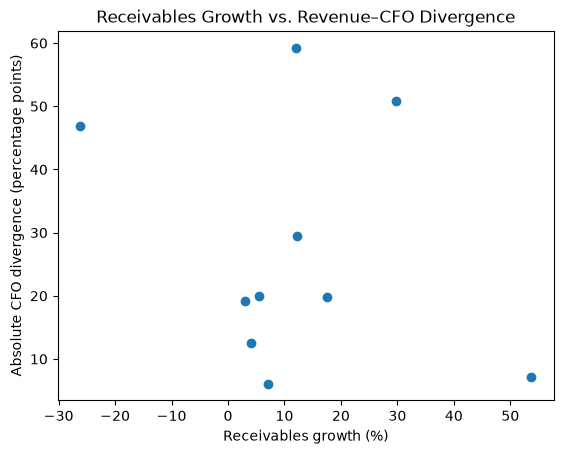

In [50]:
plt.scatter(
    analysis["receivables_growth"] * 100,
    analysis["abs_cfo_divergence"] * 100
)

plt.xlabel("Receivables growth (%)")
plt.ylabel("Absolute CFO divergence (percentage points)")
plt.title(
    "Receivables Growth vs. Revenue–CFO Divergence"
)

plt.show()

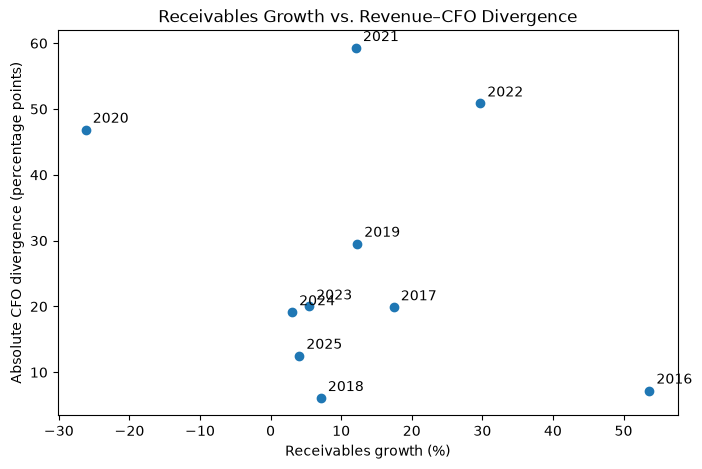

In [51]:
plt.figure(figsize=(8, 5))

plt.scatter(
    analysis["receivables_growth"] * 100,
    analysis["abs_cfo_divergence"] * 100
)

for _, row in analysis.dropna().iterrows():
    plt.annotate(
        str(int(row["year"])),
        (
            row["receivables_growth"] * 100,
            row["abs_cfo_divergence"] * 100
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Receivables growth (%)")
plt.ylabel("Absolute CFO divergence (percentage points)")
plt.title("Receivables Growth vs. Revenue–CFO Divergence")

plt.show()

In [52]:
[x for x in data["facts"]["us-gaap"].keys() if "Payable" in x]

['AccountsPayable',
 'AccountsPayableCurrent',
 'AccountsPayableTradeCurrent',
 'OtherAccountsPayableAndAccruedLiabilities']

In [53]:
payable_concepts = [
    "AccountsPayable",
    "AccountsPayableCurrent",
    "AccountsPayableTradeCurrent",
    "OtherAccountsPayableAndAccruedLiabilities",
]

for concept in payable_concepts:
    fact = data["facts"]["us-gaap"].get(concept)

    print(f"\n{'=' * 70}")
    print(concept)
    print(f"Label: {fact.get('label')}")
    print(f"Description: {fact.get('description')}")
    print(f"Units: {list(fact.get('units', {}).keys())}")


AccountsPayable
Label: Accounts Payable (Deprecated 2009-01-31)
Description: Carrying value as of the balance sheet date of liabilities incurred (and for which invoices have typically been received) and payable to vendors for goods and services received that are used in an entity's business. For classified balance sheets, used to reflect the current portion of the liabilities (due within one year or within the normal operating cycle if longer); for unclassified balance sheets, used to reflect the total liabilities (regardless of due date).
Units: ['USD']

AccountsPayableCurrent
Label: Accounts Payable, Current
Description: Carrying value as of the balance sheet date of liabilities incurred (and for which invoices have typically been received) and payable to vendors for goods and services received that are used in an entity's business. Used to reflect the current portion of the liabilities (due within one year or within the normal operating cycle if longer).
Units: ['USD']

AccountsPay

In [54]:
fact = data["facts"]["us-gaap"]["AccountsPayableTradeCurrent"]

print("Label:", fact["label"])

for unit, records in fact["units"].items():
    print("Unit:", unit)
    print("Number of facts:", len(records))

    for r in records[-10:]:
        print(
            r.get("end"),
            r.get("val"),
            r.get("fy"),
            r.get("fp"),
            r.get("form"),
            r.get("filed")
        )

Label: Accounts Payable, Trade, Current
Unit: USD
Number of facts: 124
2024-12-31 763000000 2025 Q3 10-Q 2025-11-04
2024-12-31 763000000 2025 FY 10-K 2026-02-10
2025-03-31 812000000 2025 Q1 10-Q 2025-05-06
2025-06-30 778000000 2025 Q2 10-Q 2025-08-05
2025-09-30 759000000 2025 Q3 10-Q 2025-11-04
2025-12-31 814000000 2025 FY 10-K 2026-02-10
2025-12-31 814000000 2026 Q1 10-Q 2026-05-06
2025-12-31 814000000 2026 Q2 10-Q 2026-08-03
2026-03-31 763000000 2026 Q1 10-Q 2026-05-06
2026-06-30 819000000 2026 Q2 10-Q 2026-08-03


In [55]:
payables = data["facts"]["us-gaap"]["AccountsPayableTradeCurrent"]["units"]["USD"]

payables_10k = [
    r for r in payables
    if r.get("form") == "10-K"
]

for r in payables_10k:
    print(
        r.get("end"),
        r.get("val"),
        r.get("fy"),
        r.get("filed")
    )

2010-12-31 634000000 2011 2012-02-16
2011-12-30 548000000 2011 2012-02-16
2011-12-30 548000000 2012 2013-02-20
2012-12-28 569000000 2012 2013-02-20
2012-12-28 569000000 2013 2014-02-20
2013-12-31 557000000 2013 2014-02-20
2013-12-31 557000000 2014 2015-02-19
2014-12-31 605000000 2014 2015-02-19
2014-12-31 605000000 2015 2016-02-18
2015-12-31 593000000 2015 2016-02-18
2015-12-31 593000000 2016 2017-02-21
2016-12-31 687000000 2016 2017-02-21
2016-12-31 687000000 2017 2018-02-15
2017-12-31 780000000 2017 2018-02-15
2017-12-31 783000000 2018 2019-03-01
2018-12-31 767000000 2018 2019-03-01
2018-12-31 767000000 2019 2020-02-27
2019-12-31 720000000 2019 2020-02-27
2019-12-31 720000000 2020 2021-02-18
2020-12-31 527000000 2020 2021-02-18
2020-12-31 527000000 2021 2022-02-15
2021-12-31 726000000 2021 2022-02-15
2021-12-31 726000000 2022 2023-02-14
2022-12-31 746000000 2022 2023-02-14
2022-12-31 746000000 2023 2024-02-13
2023-12-31 738000000 2023 2024-02-13
2023-12-31 738000000 2024 2025-02-11
2

In [56]:
payables_clean = (
    pd.DataFrame(payables_10k)
    .sort_values(["end", "filed"])
    .drop_duplicates(subset=["end"], keep="last")
    .copy()
)

payables_clean["fiscal_year"] = (
    pd.to_datetime(payables_clean["end"]).dt.year
)

payables_clean["payables"] = (
    payables_clean["val"] / 1_000_000
)

payables_clean = payables_clean[
    ["fiscal_year", "end", "payables", "filed"]
].reset_index(drop=True)

payables_clean

,fiscal_year,end,payables,filed
0,2010,2010-12-31,634.0,2012-02-16
1,2011,2011-12-30,548.0,2013-02-20
2,2012,2012-12-28,569.0,2014-02-20
3,2013,2013-12-31,557.0,2015-02-19
4,2014,2014-12-31,605.0,2016-02-18
5,2015,2015-12-31,593.0,2017-02-21
6,2016,2016-12-31,687.0,2018-02-15
7,2017,2017-12-31,783.0,2019-03-01
8,2018,2018-12-31,767.0,2020-02-27
9,2019,2019-12-31,720.0,2021-02-18


In [57]:
payables_clean["payables_growth"] = (
    payables_clean["payables"].pct_change()
)

payables_clean[
    ["fiscal_year", "payables", "payables_growth"]
].round(4)

,fiscal_year,payables,payables_growth
0,2010,634.0,NaN
1,2011,548.0,-0.1356
2,2012,569.0,0.0383
3,2013,557.0,-0.0211
4,2014,605.0,0.0862
5,2015,593.0,-0.0198
6,2016,687.0,0.1585
7,2017,783.0,0.1397
8,2018,767.0,-0.0204
9,2019,720.0,-0.0613


In [58]:
df = df.merge(
    payables_clean[["fiscal_year", "payables", "payables_growth"]],
    left_on="year",
    right_on="fiscal_year",
    how="left"
)


In [59]:
df = df.drop(columns="fiscal_year")

In [60]:
df.columns.tolist()

['year',
 'revenue',
 'receivables',
 'revenue_growth',
 'receivables_growth',
 'divergence',
 'abs_divergence',
 'period',
 'operating_cash_flow',
 'operating_cash_flow_growth',
 'cfo_divergence',
 'abs_cfo_divergence',
 'payables',
 'payables_growth']

In [61]:
df[
    [
        "year",
        "revenue_growth",
        "receivables_growth",
        "payables_growth",
        "operating_cash_flow_growth",
        "cfo_divergence"
    ]
].round(4)

,year,revenue_growth,receivables_growth,payables_growth,operating_cash_flow_growth,cfo_divergence
0,2015,NaN,NaN,-0.0198,NaN,NaN
1,2016,0.1785,0.5367,0.1585,0.1063,0.0722
2,2017,0.3410,0.1746,0.1397,0.5398,-0.1988
3,2018,-0.0933,0.0713,-0.0204,-0.0324,-0.0609
4,2019,0.0103,0.1228,-0.0613,-0.2851,0.2954
5,2020,-0.4959,-0.2618,-0.2681,-0.0273,-0.4686
6,2021,0.3109,0.1210,0.3776,-0.2819,0.5927
7,2022,0.4991,0.2972,0.0275,1.0076,-0.5085
8,2023,0.1415,0.0548,-0.0107,0.3415,-0.2000
9,2024,0.0585,0.0306,0.0339,-0.1328,0.1913


In [62]:
df[
    [
        "receivables_growth",
        "payables_growth",
        "cfo_divergence"
    ]
].corr().round(4)

,receivables_growth,payables_growth,cfo_divergence
receivables_growth,1.0000,0.5718,0.1887
payables_growth,0.5718,1.0000,0.6286
cfo_divergence,0.1887,0.6286,1.0000


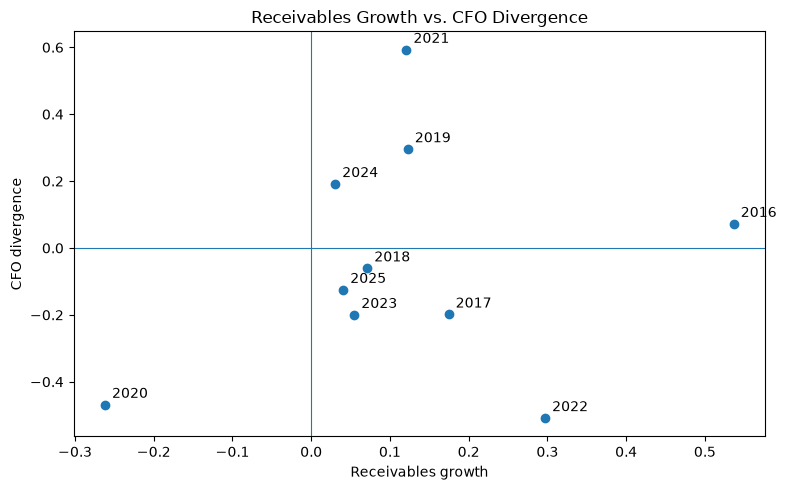

In [63]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["receivables_growth"],
    df["cfo_divergence"]
)

# Add year labels to each observation
for _, row in df.dropna(
    subset=["receivables_growth", "cfo_divergence"]
).iterrows():
    plt.annotate(
        int(row["year"]),
        (row["receivables_growth"], row["cfo_divergence"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("Receivables growth")
plt.ylabel("CFO divergence")
plt.title("Receivables Growth vs. CFO Divergence")

plt.tight_layout()
plt.show()

In [64]:
df[
    ["receivables_growth", "cfo_divergence"]
].corr().round(4)

,receivables_growth,cfo_divergence
receivables_growth,1.0000,0.1887
cfo_divergence,0.1887,1.0000


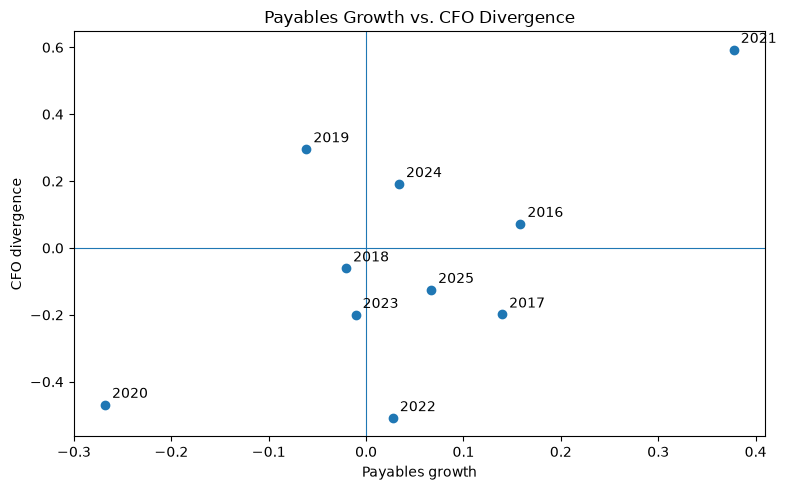

In [65]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["payables_growth"],
    df["cfo_divergence"]
)

for _, row in df.dropna(
    subset=["payables_growth", "cfo_divergence"]
).iterrows():
    plt.annotate(
        int(row["year"]),
        (row["payables_growth"], row["cfo_divergence"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("Payables growth")
plt.ylabel("CFO divergence")
plt.title("Payables Growth vs. CFO Divergence")

plt.tight_layout()
plt.show()

In [66]:
df[
    ["payables_growth", "cfo_divergence"]
].corr().round(4)

,payables_growth,cfo_divergence
payables_growth,1.0000,0.6286
cfo_divergence,0.6286,1.0000


In [67]:
df["receivables_change"] = df["receivables"].diff()
df["payables_change"] = df["payables"].diff()

In [68]:
df[
    [
        "year",
        "receivables",
        "receivables_change",
        "payables",
        "payables_change",
        "operating_cash_flow"
    ]
].round(2)

,year,receivables,receivables_change,payables,payables_change,operating_cash_flow
0,2015,1103000000,NaN,593.0,NaN,1430000000
1,2016,1695000000,592000000.0,687.0,94.0,1582000000
2,2017,1991000000,296000000.0,783.0,96.0,2436000000
3,2018,2133000000,142000000.0,767.0,-16.0,2357000000
4,2019,2395000000,262000000.0,720.0,-47.0,1685000000
5,2020,1768000000,-627000000.0,527.0,-193.0,1639000000
6,2021,1982000000,214000000.0,726.0,199.0,1177000000
7,2022,2571000000,589000000.0,746.0,20.0,2363000000
8,2023,2712000000,141000000.0,738.0,-8.0,3170000000
9,2024,2795000000,83000000.0,763.0,25.0,2749000000


In [69]:
df[
    ["receivables_change", "cfo_divergence"]
].corr().round(4)

,receivables_change,cfo_divergence
receivables_change,1.0000,0.2142
cfo_divergence,0.2142,1.0000


In [70]:
df[
    ["payables_change", "cfo_divergence"]
].corr().round(4)

,payables_change,cfo_divergence
payables_change,1.0000,0.5756
cfo_divergence,0.5756,1.0000


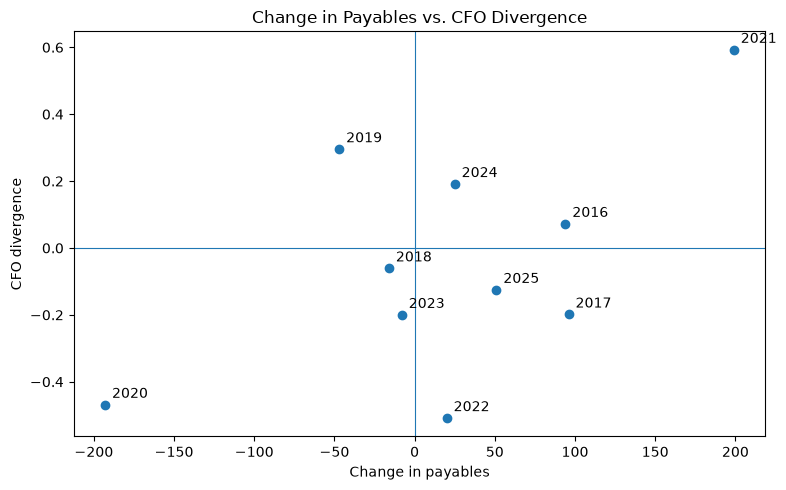

In [71]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["payables_change"],
    df["cfo_divergence"]
)

for _, row in df.dropna(
    subset=["payables_change", "cfo_divergence"]
).iterrows():
    plt.annotate(
        int(row["year"]),
        (row["payables_change"], row["cfo_divergence"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("Change in payables")
plt.ylabel("CFO divergence")
plt.title("Change in Payables vs. CFO Divergence")

plt.tight_layout()
plt.show()

In [72]:
df[
    ["payables_change", "cfo_divergence"]
].corr().round(4)

,payables_change,cfo_divergence
payables_change,1.0000,0.5756
cfo_divergence,0.5756,1.0000


In [73]:
df[
    [
        "year",
        "payables",
        "payables_change",
        "payables_growth",
        "cfo_divergence"
    ]
].round(4)

,year,payables,payables_change,payables_growth,cfo_divergence
0,2015,593.0,NaN,-0.0198,NaN
1,2016,687.0,94.0,0.1585,0.0722
2,2017,783.0,96.0,0.1397,-0.1988
3,2018,767.0,-16.0,-0.0204,-0.0609
4,2019,720.0,-47.0,-0.0613,0.2954
5,2020,527.0,-193.0,-0.2681,-0.4686
6,2021,726.0,199.0,0.3776,0.5927
7,2022,746.0,20.0,0.0275,-0.5085
8,2023,738.0,-8.0,-0.0107,-0.2000
9,2024,763.0,25.0,0.0339,0.1913


That is important for an audit-oriented analysis: we shouldn't write “higher payables cause higher CFO divergence.” A safer conclusion is that changes in payables are associated with CFO divergence in this sample, but the relationship is sensitive to a small number of exceptional years.

In [74]:
df_normal = df[
    ~df["year"].isin([2020, 2021])
]

df_normal[
    ["payables_change", "cfo_divergence"]
].corr().round(4)

,payables_change,cfo_divergence
payables_change,1.0000,-0.2305
cfo_divergence,-0.2305,1.0000


The apparent relationship between changes in payables and CFO divergence in Marriott's 2015–2025 data is largely driven by the COVID/recovery period rather than representing a consistent relationship across the full period.

In [75]:
df_normal[
    ["receivables_change", "cfo_divergence"]
].corr().round(4)

,receivables_change,cfo_divergence
receivables_change,1.0000,-0.3416
cfo_divergence,-0.3416,1.0000


Once the exceptional 2020–2021 period is removed, both relationships become moderately negative.
our analysis suggests:

Payables showed the stronger raw correlation with CFO divergence (+0.5756).
That relationship is largely associated with the unusual 2020–2021 period.
Outside that period, the relationship becomes negative (−0.2305).
Receivables behaves similarly: +0.2142 overall, but −0.3416 excluding 2020–2021.
With only 9 observations after excluding those two years, these correlations remain exploratory.

In [76]:
df["payables_change_usd"] = df["payables_change"] * 1_000_000

df["working_capital_cash_effect"] = (
    df["payables_change_usd"] - df["receivables_change"]
)

df[
    [
        "year",
        "receivables_change",
        "payables_change_usd",
        "working_capital_cash_effect",
        "operating_cash_flow"
    ]
].round(0)

,year,receivables_change,payables_change_usd,working_capital_cash_effect,operating_cash_flow
0,2015,NaN,NaN,NaN,1430000000
1,2016,592000000.0,94000000.0,-498000000.0,1582000000
2,2017,296000000.0,96000000.0,-200000000.0,2436000000
3,2018,142000000.0,-16000000.0,-158000000.0,2357000000
4,2019,262000000.0,-47000000.0,-309000000.0,1685000000
5,2020,-627000000.0,-193000000.0,434000000.0,1639000000
6,2021,214000000.0,199000000.0,-15000000.0,1177000000
7,2022,589000000.0,20000000.0,-569000000.0,2363000000
8,2023,141000000.0,-8000000.0,-149000000.0,3170000000
9,2024,83000000.0,25000000.0,-58000000.0,2749000000


In [77]:
df["working_capital_effect_pct_cfo"] = (
    df["working_capital_cash_effect"] / df["operating_cash_flow"] *100
)

df[
    [
        "year",
        "working_capital_cash_effect",
        "operating_cash_flow",
        "working_capital_effect_pct_cfo"
    ]
].round(2)

,year,working_capital_cash_effect,operating_cash_flow,working_capital_effect_pct_cfo
0,2015,NaN,1430000000,NaN
1,2016,-498000000.0,1582000000,-31.48
2,2017,-200000000.0,2436000000,-8.21
3,2018,-158000000.0,2357000000,-6.70
4,2019,-309000000.0,1685000000,-18.34
5,2020,434000000.0,1639000000,26.48
6,2021,-15000000.0,1177000000,-1.27
7,2022,-569000000.0,2363000000,-24.08
8,2023,-149000000.0,3170000000,-4.70
9,2024,-58000000.0,2749000000,-2.11


In [78]:
df["wc_effect_pct_revenue"] = (
    df["working_capital_cash_effect"] / df["revenue"] * 100
)

df["wc_effect_pct_cfo"] = (
    df["working_capital_cash_effect"] / df["operating_cash_flow"] * 100
)

In [79]:
df[
    [
        "year",
        "working_capital_cash_effect",
        "revenue",
        "operating_cash_flow",
        "wc_effect_pct_revenue",
        "wc_effect_pct_cfo"
    ]
].round(2)

,year,working_capital_cash_effect,revenue,operating_cash_flow,wc_effect_pct_revenue,wc_effect_pct_cfo
0,2015,NaN,14486000000,1430000000,NaN,NaN
1,2016,-498000000.0,17072000000,1582000000,-2.92,-31.48
2,2017,-200000000.0,22894000000,2436000000,-0.87,-8.21
3,2018,-158000000.0,20758000000,2357000000,-0.76,-6.70
4,2019,-309000000.0,20972000000,1685000000,-1.47,-18.34
5,2020,434000000.0,10571000000,1639000000,4.11,26.48
6,2021,-15000000.0,13857000000,1177000000,-0.11,-1.27
7,2022,-569000000.0,20773000000,2363000000,-2.74,-24.08
8,2023,-149000000.0,23713000000,3170000000,-0.63,-4.70
9,2024,-58000000.0,25100000000,2749000000,-0.23,-2.11


In [80]:
[x for x in data["facts"]["us-gaap"] if "Asset" in x][:50]

['AmortizationOfIntangibleAssets',
 'AssetImpairmentCharges',
 'Assets',
 'AssetsCurrent',
 'AssetsDisposedOfByMethodOtherThanSaleInPeriodOfDispositionGainLossOnDisposition',
 'AssetsDisposedOfByMethodOtherThanSaleInPeriodOfDispositionGainLossOnDisposition1',
 'AssetsHeldForSaleCurrent',
 'AssetsOfDisposalGroupIncludingDiscontinuedOperation',
 'AssetsOfDisposalGroupIncludingDiscontinuedOperationCurrent',
 'CapitalLeasedAssetsGross',
 'CapitalLeasesBalanceSheetAssetsByMajorClassNet',
 'CapitalLeasesLesseeBalanceSheetAssetsByMajorClassAccumulatedDeprecation',
 'CashFlowsBetweenSecuritizationSpecialPurposeEntitySPEAndTransferorProceedsFromNewlySecuritizedAssets',
 'CashFlowsBetweenSecuritizationSpecialPurposeEntitySPEAndTransferorPurchasesOfDelinquentOrForeclosedAssets',
 'CashFlowsBetweenTransfereeAndTransferorPurchasesOfPreviouslyTransferredFinancialAssets',
 'DeferredIncomeTaxAssetsNet',
 'DeferredTaxAssetsDeferredIncome',
 'DeferredTaxAssetsEquityMethodInvestments',
 'DeferredTaxAsset

In [81]:
[x for x in data["facts"]["us-gaap"]
 if "Income" in x or "Earnings" in x][:50]

['AccumulatedOtherComprehensiveIncomeLossAvailableForSaleSecuritiesAdjustmentNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossCumulativeChangesInNetGainLossFromCashFlowHedgesEffectNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossForeignCurrencyTranslationAdjustmentNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossNetOfTax',
 'AntidilutiveSecuritiesExcludedFromComputationOfEarningsPerShareAmount',
 'ComprehensiveIncomeNetOfTax',
 'ComprehensiveIncomeNetOfTaxIncludingPortionAttributableToNoncontrollingInterest',
 'CurrentIncomeTaxExpenseBenefit',
 'DeferredFederalIncomeTaxExpenseBenefit',
 'DeferredForeignIncomeTaxExpenseBenefit',
 'DeferredIncomeTaxAssetsNet',
 'DeferredIncomeTaxExpenseBenefit',
 'DeferredIncomeTaxLiabilities',
 'DeferredIncomeTaxLiabilitiesNet',
 'DeferredStateAndLocalIncomeTaxExpenseBenefit',
 'DeferredTaxAssetsDeferredIncome',
 'DiscontinuedOperationIncomeLossFromDiscontinuedOperationBeforeIncomeTax',
 'DiscontinuedOperationTaxEffectOfIncomeLossFromDiscontinu

In [82]:
for concept in [
    "Assets",
    "IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest"
]:
    print("\n", concept)
    print(data["facts"]["us-gaap"][concept]["label"])
    print(data["facts"]["us-gaap"][concept]["description"])
    print(data["facts"]["us-gaap"][concept]["units"].keys())


 Assets
Assets
Sum of the carrying amounts as of the balance sheet date of all assets that are recognized. Assets are probable future economic benefits obtained or controlled by an entity as a result of past transactions or events.
dict_keys(['USD'])

 IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest
Income (Loss) from Continuing Operations before Income Taxes, Noncontrolling Interest
Amount of income (loss) from continuing operations, including income (loss) from equity method investments, before deduction of income tax expense (benefit), and income (loss) attributable to noncontrolling interest.
dict_keys(['USD'])


In [83]:
for concept in [
    "Assets",
    "IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest"
]:
    print("\n" + "=" * 80)
    print(concept)

    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    for fact in facts:
        if fact.get("form") == "10-K":
            print(
                fact.get("fy"),
                fact.get("fp"),
                fact.get("end"),
                fact.get("val"),
                fact.get("accn")
            )


Assets
2009 FY 2009-01-02 8903000000 0001193125-10-030603
2009 FY 2010-01-01 7933000000 0001193125-10-030603
2010 FY 2010-01-01 7933000000 0001193125-11-039869
2010 FY 2010-12-31 8983000000 0001193125-11-039869
2011 FY 2010-12-31 8983000000 0001445305-12-000342
2011 FY 2011-12-30 5910000000 0001445305-12-000342
2012 FY 2011-12-30 5910000000 0001445305-13-000255
2012 FY 2012-12-28 6342000000 0001445305-13-000255
2013 FY 2012-12-28 6342000000 0001445305-14-000495
2013 FY 2013-12-31 6794000000 0001445305-14-000495
2014 FY 2013-12-31 6794000000 0001628280-15-000842
2014 FY 2014-12-31 6865000000 0001628280-15-000842
2015 FY 2014-12-31 6833000000 0001628280-16-011346
2015 FY 2015-12-31 6082000000 0001628280-16-011346
2016 FY 2015-12-31 6082000000 0001628280-17-001506
2016 FY 2016-12-31 24140000000 0001628280-17-001506
2017 FY 2016-12-31 24140000000 0001628280-18-001756
2017 FY 2017-12-31 23948000000 0001628280-18-001756
2018 FY 2017-12-31 23846000000 0001628280-19-002337
2018 FY 2018-12-31 

In [84]:
def get_original_annual_fact(data, concept, start_year=2015, end_year=2025):
    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    records = []

    for fact in facts:
        if fact.get("form") != "10-K":
            continue

        fy = fact.get("fy")
        end = fact.get("end")

        if fy is None or end is None:
            continue

        if start_year <= fy <= end_year:
            records.append({
                "year": fy,
                "end": end,
                "value": fact["val"],
                "filed": fact.get("filed"),
                "accn": fact.get("accn")
            })

    return pd.DataFrame(records)

In [85]:
assets_df = get_original_annual_fact(
    data,
    "Assets"
)

pbt_df = get_original_annual_fact(
    data,
    "IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest"
)

In [86]:
assets_df

,year,end,value,filed,accn
0,2015,2014-12-31,6833000000,2016-02-18,0001628280-16-011346
1,2015,2015-12-31,6082000000,2016-02-18,0001628280-16-011346
2,2016,2015-12-31,6082000000,2017-02-21,0001628280-17-001506
3,2016,2016-12-31,24140000000,2017-02-21,0001628280-17-001506
4,2017,2016-12-31,24140000000,2018-02-15,0001628280-18-001756
5,2017,2017-12-31,23948000000,2018-02-15,0001628280-18-001756
6,2018,2017-12-31,23846000000,2019-03-01,0001628280-19-002337
7,2018,2018-12-31,23696000000,2019-03-01,0001628280-19-002337
8,2019,2018-12-31,23696000000,2020-02-27,0001628280-20-002376
9,2019,2019-12-31,25051000000,2020-02-27,0001628280-20-002376


In [87]:
pbt_df

,year,end,value,filed,accn
0,2015,2013-12-31,897000000,2016-02-18,0001628280-16-011346
1,2015,2014-12-31,1088000000,2016-02-18,0001628280-16-011346
2,2016,2014-12-31,1088000000,2017-02-21,0001628280-17-001506
3,2015,2015-12-31,1255000000,2016-02-18,0001628280-16-011346
4,2016,2015-12-31,1255000000,2017-02-21,0001628280-17-001506
5,2017,2015-12-31,1255000000,2018-02-15,0001628280-18-001756
6,2016,2016-12-31,1184000000,2017-02-21,0001628280-17-001506
7,2017,2016-12-31,1184000000,2018-02-15,0001628280-18-001756
8,2018,2016-12-31,1239000000,2019-03-01,0001628280-19-002337
9,2017,2017-12-31,2836000000,2018-02-15,0001628280-18-001756


In [88]:
assets_annual = assets_df[
    assets_df["end"].str[:4].astype(int) == assets_df["year"]
].copy()

pbt_annual = pbt_df[
    (pbt_df["end"].str[:4].astype(int) == pbt_df["year"])
    & (pbt_df["end"].str.endswith("-12-31"))
].copy()

In [89]:
assets_annual

,year,end,value,filed,accn
1,2015,2015-12-31,6082000000,2016-02-18,0001628280-16-011346
3,2016,2016-12-31,24140000000,2017-02-21,0001628280-17-001506
5,2017,2017-12-31,23948000000,2018-02-15,0001628280-18-001756
7,2018,2018-12-31,23696000000,2019-03-01,0001628280-19-002337
9,2019,2019-12-31,25051000000,2020-02-27,0001628280-20-002376
11,2020,2020-12-31,24701000000,2021-02-18,0001628280-21-002433
13,2021,2021-12-31,25553000000,2022-02-15,0001628280-22-002666
15,2022,2022-12-31,24815000000,2023-02-14,0001628280-23-003485
17,2023,2023-12-31,25674000000,2024-02-13,0001628280-24-004372
19,2024,2024-12-31,26182000000,2025-02-11,0001628280-25-004818


In [90]:
pbt_annual

,year,end,value,filed,accn
3,2015,2015-12-31,1255000000,2016-02-18,0001628280-16-011346
6,2016,2016-12-31,1184000000,2017-02-21,0001628280-17-001506
9,2017,2017-12-31,2836000000,2018-02-15,0001628280-18-001756
15,2018,2018-12-31,2345000000,2019-03-01,0001628280-19-002337
18,2019,2019-12-31,1599000000,2020-02-27,0001628280-20-002376
21,2020,2020-12-31,-466000000,2021-02-18,0001628280-21-002433
24,2021,2021-12-31,1180000000,2022-02-15,0001628280-22-002666
27,2022,2022-12-31,3114000000,2023-02-14,0001628280-23-003485
30,2023,2023-12-31,3378000000,2024-02-13,0001628280-24-004372
33,2024,2024-12-31,3151000000,2025-02-11,0001628280-25-004818


In [91]:
benchmark_df = (
    assets_annual[["year", "value"]]
    .rename(columns={"value": "total_assets"})
    .merge(
        pbt_annual[["year", "value"]]
        .rename(columns={"value": "profit_before_tax"}),
        on="year",
        how="inner"
    )
)

df = df.merge(
    benchmark_df,
    on="year",
    how="left"
)

df[[
    "year",
    "revenue",
    "operating_cash_flow",
    "total_assets",
    "profit_before_tax"
]]

,year,revenue,operating_cash_flow,total_assets,profit_before_tax
0,2015,14486000000,1430000000,6082000000,1255000000
1,2016,17072000000,1582000000,24140000000,1184000000
2,2017,22894000000,2436000000,23948000000,2836000000
3,2018,20758000000,2357000000,23696000000,2345000000
4,2019,20972000000,1685000000,25051000000,1599000000
5,2020,10571000000,1639000000,24701000000,-466000000
6,2021,13857000000,1177000000,25553000000,1180000000
7,2022,20773000000,2363000000,24815000000,3114000000
8,2023,23713000000,3170000000,25674000000,3378000000
9,2024,25100000000,2749000000,26182000000,3151000000


In [92]:
df["wc_effect_pct_assets"] = (
    df["working_capital_cash_effect"]
    / df["total_assets"]
    * 100
)

df[[
    "year",
    "working_capital_cash_effect",
    "total_assets",
    "wc_effect_pct_assets"
]]

,year,working_capital_cash_effect,total_assets,wc_effect_pct_assets
0,2015,NaN,6082000000,NaN
1,2016,-498000000.0,24140000000,-2.062966
2,2017,-200000000.0,23948000000,-0.835143
3,2018,-158000000.0,23696000000,-0.666779
4,2019,-309000000.0,25051000000,-1.233484
5,2020,434000000.0,24701000000,1.757014
6,2021,-15000000.0,25553000000,-0.058702
7,2022,-569000000.0,24815000000,-2.292968
8,2023,-149000000.0,25674000000,-0.580354
9,2024,-58000000.0,26182000000,-0.221526


In [93]:
df["wc_effect_pct_pbt"] = np.where(
    df["profit_before_tax"] > 0,
    df["working_capital_cash_effect"]
    / df["profit_before_tax"]
    * 100,
    np.nan
)

df[[
    "year",
    "working_capital_cash_effect",
    "profit_before_tax",
    "wc_effect_pct_pbt"
]]

,year,working_capital_cash_effect,profit_before_tax,wc_effect_pct_pbt
0,2015,NaN,1255000000,NaN
1,2016,-498000000.0,1184000000,-42.060811
2,2017,-200000000.0,2836000000,-7.052186
3,2018,-158000000.0,2345000000,-6.737740
4,2019,-309000000.0,1599000000,-19.324578
5,2020,434000000.0,-466000000,NaN
6,2021,-15000000.0,1180000000,-1.271186
7,2022,-569000000.0,3114000000,-18.272319
8,2023,-149000000.0,3378000000,-4.410894
9,2024,-58000000.0,3151000000,-1.840685


In [94]:
audit_flags = df[
    (
        df["wc_effect_pct_cfo"].abs() >= 15
    )
    |
    (
        df["wc_effect_pct_pbt"].abs() >= 15
    )
].copy()

audit_flags = audit_flags[
    [
        "year",
        "working_capital_cash_effect",
        "wc_effect_pct_cfo",
        "wc_effect_pct_pbt"
    ]
].sort_values("year")

audit_flags

,year,working_capital_cash_effect,wc_effect_pct_cfo,wc_effect_pct_pbt
1,2016,-498000000.0,-31.479140,-42.060811
4,2019,-309000000.0,-18.338279,-19.324578
5,2020,434000000.0,26.479561,NaN
7,2022,-569000000.0,-24.079560,-18.272319


In [95]:
def get_flag_reason(row, threshold=15):
    reasons = []

    if abs(row["wc_effect_pct_cfo"]) >= threshold:
        reasons.append("Large relative to CFO")

    if pd.notna(row["wc_effect_pct_pbt"]) and abs(row["wc_effect_pct_pbt"]) >= threshold:
        reasons.append("Large relative to PBT")

    return " + ".join(reasons)


audit_flags["flag_reason"] = audit_flags.apply(
    get_flag_reason,
    axis=1
)

audit_flags

,year,working_capital_cash_effect,wc_effect_pct_cfo,wc_effect_pct_pbt,flag_reason
1,2016,-498000000.0,-31.479140,-42.060811,Large relative to CFO + Large relative to PBT
4,2019,-309000000.0,-18.338279,-19.324578,Large relative to CFO + Large relative to PBT
5,2020,434000000.0,26.479561,NaN,Large relative to CFO
7,2022,-569000000.0,-24.079560,-18.272319,Large relative to CFO + Large relative to PBT


In [96]:
audit_flags_display = audit_flags.copy()

audit_flags_display["working_capital_cash_effect"] = (
    audit_flags_display["working_capital_cash_effect"] / 1_000_000
).round(0)

audit_flags_display["wc_effect_pct_cfo"] = (
    audit_flags_display["wc_effect_pct_cfo"].round(1)
)

audit_flags_display["wc_effect_pct_pbt"] = (
    audit_flags_display["wc_effect_pct_pbt"].round(1)
)

audit_flags_display = audit_flags_display.rename(
    columns={
        "working_capital_cash_effect": "WC effect ($M)",
        "wc_effect_pct_cfo": "WC effect / CFO (%)",
        "wc_effect_pct_pbt": "WC effect / PBT (%)",
        "flag_reason": "Flag reason"
    }
)

audit_flags_display

,year,WC effect ($M),WC effect / CFO (%),WC effect / PBT (%),Flag reason
1,2016,-498.0,-31.5,-42.1,Large relative to CFO + Large relative to PBT
4,2019,-309.0,-18.3,-19.3,Large relative to CFO + Large relative to PBT
5,2020,434.0,26.5,NaN,Large relative to CFO
7,2022,-569.0,-24.1,-18.3,Large relative to CFO + Large relative to PBT


In [97]:
def get_audit_interpretation(row):
    year = row["year"]

    if year == 2016:
        return (
            "Large working-capital cash outflow relative to CFO and PBT",
            "Investigate receivables growth, collection patterns, and acquisition-related effects"
        )

    if year == 2019:
        return (
            "Large working-capital cash outflow relative to CFO and PBT",
            "Investigate receivables increase and deterioration in operating cash conversion"
        )

    if year == 2020:
        return (
            "Large working-capital cash inflow during an exceptional year",
            "Investigate COVID-related changes in activity, collections, and payment patterns"
        )

    if year == 2022:
        return (
            "Largest working-capital cash outflow in the period",
            "Investigate receivables growth, collection patterns, and subsequent cash receipts"
        )

    return ("", "")

In [98]:
audit_flags[
    ["analytical_signal", "audit_focus"]
] = audit_flags.apply(
    get_audit_interpretation,
    axis=1,
    result_type="expand"
)
audit_flags

,year,working_capital_cash_effect,wc_effect_pct_cfo,wc_effect_pct_pbt,flag_reason,analytical_signal,audit_focus
1,2016,-498000000.0,-31.479140,-42.060811,Large relative to CFO + Large relative to PBT,Large working-capital cash outflow relative to...,"Investigate receivables growth, collection pat..."
4,2019,-309000000.0,-18.338279,-19.324578,Large relative to CFO + Large relative to PBT,Large working-capital cash outflow relative to...,Investigate receivables increase and deteriora...
5,2020,434000000.0,26.479561,NaN,Large relative to CFO,Large working-capital cash inflow during an ex...,"Investigate COVID-related changes in activity,..."
7,2022,-569000000.0,-24.079560,-18.272319,Large relative to CFO + Large relative to PBT,Largest working-capital cash outflow in the pe...,"Investigate receivables growth, collection pat..."


In [99]:
audit_interpretation = audit_flags_display.copy()

audit_interpretation[
    ["analytical_signal", "audit_focus"]
] = audit_flags[
    ["analytical_signal", "audit_focus"]
].values

audit_interpretation

,year,WC effect ($M),WC effect / CFO (%),WC effect / PBT (%),Flag reason,analytical_signal,audit_focus
1,2016,-498.0,-31.5,-42.1,Large relative to CFO + Large relative to PBT,Large working-capital cash outflow relative to...,"Investigate receivables growth, collection pat..."
4,2019,-309.0,-18.3,-19.3,Large relative to CFO + Large relative to PBT,Large working-capital cash outflow relative to...,Investigate receivables increase and deteriora...
5,2020,434.0,26.5,NaN,Large relative to CFO,Large working-capital cash inflow during an ex...,"Investigate COVID-related changes in activity,..."
7,2022,-569.0,-24.1,-18.3,Large relative to CFO + Large relative to PBT,Largest working-capital cash outflow in the pe...,"Investigate receivables growth, collection pat..."


In [100]:
df.loc[
    df["year"] == 2022,
    [
        "year",
        "revenue_growth",
        "receivables_growth",
        "receivables_change",
        "working_capital_cash_effect",
        "operating_cash_flow"
    ]
]

,year,revenue_growth,receivables_growth,receivables_change,working_capital_cash_effect,operating_cash_flow
7,2022,0.499098,0.297175,589000000.0,-569000000.0,2363000000


In [101]:
df["receivables_revenue_growth_gap"] = (
    df["receivables_growth"]
    - df["revenue_growth"]
)

df[[
    "year",
    "revenue_growth",
    "receivables_growth",
    "receivables_revenue_growth_gap"
]].round(4)

,year,revenue_growth,receivables_growth,receivables_revenue_growth_gap
0,2015,NaN,NaN,NaN
1,2016,0.1785,0.5367,0.3582
2,2017,0.3410,0.1746,-0.1664
3,2018,-0.0933,0.0713,0.1646
4,2019,0.0103,0.1228,0.1125
5,2020,-0.4959,-0.2618,0.2342
6,2021,0.3109,0.1210,-0.1898
7,2022,0.4991,0.2972,-0.2019
8,2023,0.1415,0.0548,-0.0867
9,2024,0.0585,0.0306,-0.0279


In [102]:
comparison_years = [2016, 2019, 2020]

audit_comparison = df[
    df["year"].isin(comparison_years)
][[
    "year",
    "revenue",
    "revenue_growth",
    "receivables",
    "receivables_growth",
    "receivables_revenue_growth_gap",
    "working_capital_cash_effect",
    "operating_cash_flow",
    "wc_effect_pct_cfo",
    "profit_before_tax",
    "wc_effect_pct_pbt"
]].copy()

audit_comparison

,year,revenue,revenue_growth,receivables,receivables_growth,receivables_revenue_growth_gap,working_capital_cash_effect,operating_cash_flow,wc_effect_pct_cfo,profit_before_tax,wc_effect_pct_pbt
1,2016,17072000000,0.178517,1695000000,0.536718,0.358201,-498000000.0,1582000000,-31.479140,1184000000,-42.060811
4,2019,20972000000,0.010309,2395000000,0.122832,0.112522,-309000000.0,1685000000,-18.338279,1599000000,-19.324578
5,2020,10571000000,-0.495947,1768000000,-0.261795,0.234152,434000000.0,1639000000,26.479561,-466000000,NaN


In [103]:
audit_comparison_display = audit_comparison.copy()

for col in [
    "revenue",
    "receivables",
    "working_capital_cash_effect",
    "operating_cash_flow",
    "profit_before_tax"
]:
    audit_comparison_display[col] = (
        audit_comparison_display[col] / 1_000_000
    ).round(0)

for col in [
    "revenue_growth",
    "receivables_growth",
    "receivables_revenue_growth_gap"
]:
    audit_comparison_display[col] = (
        audit_comparison_display[col] * 100
    ).round(1)

for col in [
    "wc_effect_pct_cfo",
    "wc_effect_pct_pbt"
]:
    audit_comparison_display[col] = (
        audit_comparison_display[col]
    ).round(1)

audit_comparison_display

,year,revenue,revenue_growth,receivables,receivables_growth,receivables_revenue_growth_gap,working_capital_cash_effect,operating_cash_flow,wc_effect_pct_cfo,profit_before_tax,wc_effect_pct_pbt
1,2016,17072.0,17.9,1695.0,53.7,35.8,-498.0,1582.0,-31.5,1184.0,-42.1
4,2019,20972.0,1.0,2395.0,12.3,11.3,-309.0,1685.0,-18.3,1599.0,-19.3
5,2020,10571.0,-49.6,1768.0,-26.2,23.4,434.0,1639.0,26.5,-466.0,NaN


In [104]:
comparison_years = [2016, 2019, 2020, 2022]

audit_comparison = df[
    df["year"].isin(comparison_years)
][[
    "year",
    "revenue_growth",
    "receivables_growth",
    "receivables_revenue_growth_gap",
    "working_capital_cash_effect",
    "wc_effect_pct_cfo",
    "wc_effect_pct_pbt"
]].copy()

audit_comparison

,year,revenue_growth,receivables_growth,receivables_revenue_growth_gap,working_capital_cash_effect,wc_effect_pct_cfo,wc_effect_pct_pbt
1,2016,0.178517,0.536718,0.358201,-498000000.0,-31.479140,-42.060811
4,2019,0.010309,0.122832,0.112522,-309000000.0,-18.338279,-19.324578
5,2020,-0.495947,-0.261795,0.234152,434000000.0,26.479561,NaN
7,2022,0.499098,0.297175,-0.201923,-569000000.0,-24.079560,-18.272319


In [105]:
audit_comparison_display = audit_comparison.copy()

audit_comparison_display["working_capital_cash_effect"] = (
    audit_comparison_display["working_capital_cash_effect"]
    / 1_000_000
).round(0)

for col in [
    "revenue_growth",
    "receivables_growth",
    "receivables_revenue_growth_gap"
]:
    audit_comparison_display[col] = (
        audit_comparison_display[col] * 100
    ).round(1)

for col in [
    "wc_effect_pct_cfo",
    "wc_effect_pct_pbt"
]:
    audit_comparison_display[col] = (
        audit_comparison_display[col]
    ).round(1)

audit_comparison_display

,year,revenue_growth,receivables_growth,receivables_revenue_growth_gap,working_capital_cash_effect,wc_effect_pct_cfo,wc_effect_pct_pbt
1,2016,17.9,53.7,35.8,-498.0,-31.5,-42.1
4,2019,1.0,12.3,11.3,-309.0,-18.3,-19.3
5,2020,-49.6,-26.2,23.4,434.0,26.5,NaN
7,2022,49.9,29.7,-20.2,-569.0,-24.1,-18.3


In [106]:
def get_growth_signal(row):
    gap = row["receivables_revenue_growth_gap"]

    if gap >= 0.10:
        return "Receivables grew materially faster than revenue"
    elif gap <= -0.10:
        return "Revenue grew materially faster than receivables"
    else:
        return "Receivables and revenue growth broadly aligned"


audit_comparison["growth_relationship_signal"] = audit_comparison.apply(
    get_growth_signal,
    axis=1
)

audit_comparison[
    [
        "year",
        "receivables_revenue_growth_gap",
        "growth_relationship_signal"
    ]
]

,year,receivables_revenue_growth_gap,growth_relationship_signal
1,2016,0.358201,Receivables grew materially faster than revenue
4,2019,0.112522,Receivables grew materially faster than revenue
5,2020,0.234152,Receivables grew materially faster than revenue
7,2022,-0.201923,Revenue grew materially faster than receivables


In [107]:
def get_cash_flow_signal(row, threshold=15):
    pct = abs(row["wc_effect_pct_cfo"])

    if pct >= threshold:
        return "Large relative to CFO"
    else:
        return "Not large relative to CFO"


audit_comparison["cash_flow_signal"] = audit_comparison.apply(
    get_cash_flow_signal,
    axis=1
)

audit_comparison[
    [
        "year",
        "wc_effect_pct_cfo",
        "cash_flow_signal"
    ]
]

,year,wc_effect_pct_cfo,cash_flow_signal
1,2016,-31.479140,Large relative to CFO
4,2019,-18.338279,Large relative to CFO
5,2020,26.479561,Large relative to CFO
7,2022,-24.079560,Large relative to CFO


In [108]:
def get_profit_signal(row, threshold=15):
    pct = row["wc_effect_pct_pbt"]

    if pd.isna(pct):
        return "Not applicable"
    elif abs(pct) >= threshold:
        return "Large relative to PBT"
    else:
        return "Not large relative to PBT"


audit_comparison["profit_signal"] = audit_comparison.apply(
    get_profit_signal,
    axis=1
)

audit_comparison[
    [
        "year",
        "wc_effect_pct_pbt",
        "profit_signal"
    ]
]

,year,wc_effect_pct_pbt,profit_signal
1,2016,-42.060811,Large relative to PBT
4,2019,-19.324578,Large relative to PBT
5,2020,NaN,Not applicable
7,2022,-18.272319,Large relative to PBT


In [109]:
def get_context_signal(row):
    year = row["year"]

    if year == 2016:
        return "Starwood acquisition year"
    elif year == 2020:
        return "COVID-19 disruption year"
    else:
        return "No major exceptional context identified"


audit_comparison["context_signal"] = audit_comparison.apply(
    get_context_signal,
    axis=1
)

audit_comparison[
    [
        "year",
        "growth_relationship_signal",
        "cash_flow_signal",
        "profit_signal",
        "context_signal"
    ]
]

,year,growth_relationship_signal,cash_flow_signal,profit_signal,context_signal
1,2016,Receivables grew materially faster than revenue,Large relative to CFO,Large relative to PBT,Starwood acquisition year
4,2019,Receivables grew materially faster than revenue,Large relative to CFO,Large relative to PBT,No major exceptional context identified
5,2020,Receivables grew materially faster than revenue,Large relative to CFO,Not applicable,COVID-19 disruption year
7,2022,Revenue grew materially faster than receivables,Large relative to CFO,Large relative to PBT,No major exceptional context identified


In [110]:
final_audit_flags = audit_comparison[
    [
        "year",
        "growth_relationship_signal",
        "cash_flow_signal",
        "profit_signal",
        "context_signal"
    ]
].copy()

final_audit_flags

,year,growth_relationship_signal,cash_flow_signal,profit_signal,context_signal
1,2016,Receivables grew materially faster than revenue,Large relative to CFO,Large relative to PBT,Starwood acquisition year
4,2019,Receivables grew materially faster than revenue,Large relative to CFO,Large relative to PBT,No major exceptional context identified
5,2020,Receivables grew materially faster than revenue,Large relative to CFO,Not applicable,COVID-19 disruption year
7,2022,Revenue grew materially faster than receivables,Large relative to CFO,Large relative to PBT,No major exceptional context identified


In [111]:
[key for key in data["facts"]["us-gaap"].keys()
 if any(word in key.lower()
        for word in ["interest", "depreciation", "amortization"])]

['AccumulatedDepreciationDepletionAndAmortizationPropertyPlantAndEquipment',
 'AmortizationOfIntangibleAssets',
 'CapitalizedContractCostAmortization',
 'CapitalLeasesFutureMinimumPaymentsInterestIncludedInPayments',
 'ComprehensiveIncomeNetOfTaxIncludingPortionAttributableToNoncontrollingInterest',
 'DebtInstrumentInterestRateStatedPercentage',
 'Depreciation',
 'DepreciationAmortizationAndAccretionNet',
 'DepreciationAndAmortization',
 'DepreciationDepletionAndAmortization',
 'FinanceLeaseInterestPaymentOnLiability',
 'FiniteLivedIntangibleAssetsAccumulatedAmortization',
 'FiniteLivedIntangibleAssetsAmortizationExpense',
 'FiniteLivedIntangibleAssetsAmortizationExpenseNextTwelveMonths',
 'FiniteLivedIntangibleAssetsAmortizationExpenseYearFive',
 'FiniteLivedIntangibleAssetsAmortizationExpenseYearFour',
 'FiniteLivedIntangibleAssetsAmortizationExpenseYearThree',
 'FiniteLivedIntangibleAssetsAmortizationExpenseYearTwo',
 'FutureAmortizationExpenseYearFive',
 'FutureAmortizationExpenseY

In [112]:
for concept in [
    "InterestExpense",
    "DepreciationAndAmortization"
]:
    print("=" * 80)
    print(concept)

    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    for fact in facts:
        print(
            fact.get("fy"),
            fact.get("fp"),
            fact.get("end"),
            fact.get("val"),
            fact.get("filed"),
            fact.get("accn")
        )

InterestExpense
2009 FY 2007-12-28 184000000 2010-02-12 0001193125-10-030603
2009 Q2 2008-06-13 80000000 2009-07-17 0001193125-09-150935
2009 Q2 2008-06-13 38000000 2009-07-17 0001193125-09-150935
2009 Q3 2008-09-05 113000000 2009-10-09 0001193125-09-206036
2009 Q3 2008-09-05 33000000 2009-10-09 0001193125-09-206036
2009 FY 2009-01-02 163000000 2010-02-12 0001193125-10-030603
2010 FY 2009-01-02 163000000 2011-02-18 0001193125-11-039869
2010 Q1 2009-03-27 29000000 2010-04-23 0001193125-10-091169
2010 Q1 2009-03-27 29000000 2010-04-28 0001193125-10-096111
2009 Q2 2009-06-19 57000000 2009-07-17 0001193125-09-150935
2010 Q2 2009-06-19 57000000 2010-07-16 0001193125-10-160212
2009 Q2 2009-06-19 28000000 2009-07-17 0001193125-09-150935
2010 Q2 2009-06-19 28000000 2010-07-16 0001193125-10-160212
2009 Q3 2009-09-11 84000000 2009-10-09 0001193125-09-206036
2010 Q3 2009-09-11 84000000 2010-10-08 0001193125-10-226672
2009 Q3 2009-09-11 27000000 2009-10-09 0001193125-09-206036
2010 Q3 2009-09-11 2

In [113]:
for concept in [
    "AmortizationOfIntangibleAssets",
    "FiniteLivedIntangibleAssetsAmortizationExpense"
]:
    print("=" * 80)
    print(concept)

    facts = data["facts"]["us-gaap"].get(concept)

    if facts is None:
        print("Concept not found")
        continue

    print("Label:", facts.get("label"))
    print("Description:", facts.get("description"))
    print("Units:", facts["units"].keys())

AmortizationOfIntangibleAssets
Label: Amortization of Intangible Assets
Description: The aggregate expense charged against earnings to allocate the cost of intangible assets (nonphysical assets not used in production) in a systematic and rational manner to the periods expected to benefit from such assets. As a noncash expense, this element is added back to net income when calculating cash provided by or used in operations using the indirect method.
Units: dict_keys(['USD'])
FiniteLivedIntangibleAssetsAmortizationExpense
Label: Finite-Lived Intangible Assets, Amortization Expense (Deprecated 2012-01-31)
Description: Aggregate amount of intangible asset amortization recognized as expense during the period.
Units: dict_keys(['USD'])


In [114]:
facts = data["facts"]["us-gaap"]["AmortizationOfIntangibleAssets"]

for unit, records in facts["units"].items():
    print("UNIT:", unit)

    for record in records:
        if record.get("fy", 0) >= 2015:
            print(
                record.get("fy"),
                record.get("fp"),
                record.get("end"),
                record.get("val"),
                record.get("filed"),
                record.get("accn")
            )

UNIT: USD
2015 FY 2013-12-31 68000000 2016-02-18 0001628280-16-011346
2015 FY 2014-12-31 64000000 2016-02-18 0001628280-16-011346
2016 FY 2014-12-31 64000000 2017-02-21 0001628280-17-001506
2015 FY 2015-12-31 65000000 2016-02-18 0001628280-16-011346
2016 FY 2015-12-31 65000000 2017-02-21 0001628280-17-001506
2017 FY 2015-12-31 65000000 2018-02-15 0001628280-18-001756
2016 FY 2016-12-31 87000000 2017-02-21 0001628280-17-001506
2017 FY 2016-12-31 87000000 2018-02-15 0001628280-18-001756
2017 FY 2017-12-31 185000000 2018-02-15 0001628280-18-001756
2024 FY 2022-12-31 197000000 2025-02-11 0001628280-25-004818
2024 FY 2023-12-31 226000000 2025-02-11 0001628280-25-004818
2025 FY 2023-12-31 226000000 2026-02-10 0001048286-26-000007
2024 FY 2024-12-31 255000000 2025-02-11 0001628280-25-004818
2025 FY 2024-12-31 255000000 2026-02-10 0001048286-26-000007
2025 FY 2025-12-31 313000000 2026-02-10 0001048286-26-000007


In [115]:
concepts = [
    "AmortizationOfIntangibleAssets",
    "DepreciationAndAmortization",
    "DepreciationAmortizationAndAccretionNet"
]

for concept in concepts:
    print("=" * 80)
    print(concept)

    facts = data["facts"]["us-gaap"].get(concept)

    if facts is None:
        print("Concept not found")
        continue

    print("Label:", facts.get("label"))
    print("Description:", facts.get("description"))

AmortizationOfIntangibleAssets
Label: Amortization of Intangible Assets
Description: The aggregate expense charged against earnings to allocate the cost of intangible assets (nonphysical assets not used in production) in a systematic and rational manner to the periods expected to benefit from such assets. As a noncash expense, this element is added back to net income when calculating cash provided by or used in operations using the indirect method.
DepreciationAndAmortization
Label: Depreciation, Depletion and Amortization, Nonproduction
Description: The current period expense charged against earnings on long-lived, physical assets not used in production, and which are not intended for resale, to allocate or recognize the cost of such assets over their useful lives; or to record the reduction in book value of an intangible asset over the benefit period of such asset; or to reflect consumption during the period of an asset that is not used in production.
DepreciationAmortizationAndAccre

In [116]:
concepts = [
    "AmortizationOfIntangibleAssets",
    "DepreciationAndAmortization",
    "DepreciationAmortizationAndAccretionNet"
]

for concept in concepts:
    print("=" * 80)
    print(concept)

    facts = data["facts"]["us-gaap"].get(concept)

    if facts is None:
        print("Concept not found")
        continue

    print("Label:", facts.get("label"))
    print("Description:", facts.get("description"))

AmortizationOfIntangibleAssets
Label: Amortization of Intangible Assets
Description: The aggregate expense charged against earnings to allocate the cost of intangible assets (nonphysical assets not used in production) in a systematic and rational manner to the periods expected to benefit from such assets. As a noncash expense, this element is added back to net income when calculating cash provided by or used in operations using the indirect method.
DepreciationAndAmortization
Label: Depreciation, Depletion and Amortization, Nonproduction
Description: The current period expense charged against earnings on long-lived, physical assets not used in production, and which are not intended for resale, to allocate or recognize the cost of such assets over their useful lives; or to record the reduction in book value of an intangible asset over the benefit period of such asset; or to reflect consumption during the period of an asset that is not used in production.
DepreciationAmortizationAndAccre

In [117]:
concept = "Depreciation"

facts = data["facts"]["us-gaap"].get(concept)

print("Label:", facts.get("label"))
print("Description:", facts.get("description"))
print("Units:", facts["units"].keys())

Label: Depreciation
Description: The amount of expense recognized in the current period that reflects the allocation of the cost of tangible assets over the assets' useful lives. Includes production and non-production related depreciation.
Units: dict_keys(['USD'])


In [118]:
concept = "AmortizationOfIntangibleAssets"

facts = data["facts"]["us-gaap"][concept]

for unit, records in facts["units"].items():
    print("UNIT:", unit)

    for record in records:
        if record.get("fp") == "FY" and 2015 <= record.get("fy", 0) <= 2025:
            print(
                record.get("fy"),
                record.get("end"),
                record.get("val"),
                record.get("filed"),
                record.get("accn")
            )

UNIT: USD
2015 2013-12-31 68000000 2016-02-18 0001628280-16-011346
2015 2014-12-31 64000000 2016-02-18 0001628280-16-011346
2016 2014-12-31 64000000 2017-02-21 0001628280-17-001506
2015 2015-12-31 65000000 2016-02-18 0001628280-16-011346
2016 2015-12-31 65000000 2017-02-21 0001628280-17-001506
2017 2015-12-31 65000000 2018-02-15 0001628280-18-001756
2016 2016-12-31 87000000 2017-02-21 0001628280-17-001506
2017 2016-12-31 87000000 2018-02-15 0001628280-18-001756
2017 2017-12-31 185000000 2018-02-15 0001628280-18-001756
2024 2022-12-31 197000000 2025-02-11 0001628280-25-004818
2024 2023-12-31 226000000 2025-02-11 0001628280-25-004818
2025 2023-12-31 226000000 2026-02-10 0001048286-26-000007
2024 2024-12-31 255000000 2025-02-11 0001628280-25-004818
2025 2024-12-31 255000000 2026-02-10 0001048286-26-000007
2025 2025-12-31 313000000 2026-02-10 0001048286-26-000007


In [119]:
concept = "Depreciation"

facts = data["facts"]["us-gaap"][concept]

for unit, records in facts["units"].items():
    print("UNIT:", unit)

    for record in records:
        if record.get("fp") == "FY" and 2015 <= record.get("fy", 0) <= 2025:
            print(
                record.get("fy"),
                record.get("end"),
                record.get("val"),
                record.get("filed"),
                record.get("accn")
            )

UNIT: USD
2015 2013-12-31 107000000 2016-02-18 0001628280-16-011346
2015 2014-12-31 135000000 2016-02-18 0001628280-16-011346
2016 2014-12-31 135000000 2017-02-21 0001628280-17-001506
2015 2015-12-31 132000000 2016-02-18 0001628280-16-011346
2016 2015-12-31 132000000 2017-02-21 0001628280-17-001506
2017 2015-12-31 132000000 2018-02-15 0001628280-18-001756
2016 2016-12-31 157000000 2017-02-21 0001628280-17-001506
2017 2016-12-31 157000000 2018-02-15 0001628280-18-001756
2018 2016-12-31 157000000 2019-03-01 0001628280-19-002337
2017 2017-12-31 231000000 2018-02-15 0001628280-18-001756
2018 2017-12-31 231000000 2019-03-01 0001628280-19-002337
2019 2017-12-31 231000000 2020-02-27 0001628280-20-002376
2018 2018-12-31 256000000 2019-03-01 0001628280-19-002337
2019 2018-12-31 256000000 2020-02-27 0001628280-20-002376
2020 2018-12-31 256000000 2021-02-18 0001628280-21-002433
2019 2019-12-31 346000000 2020-02-27 0001628280-20-002376
2020 2019-12-31 346000000 2021-02-18 0001628280-21-002433
2021

In [120]:
concept = data["facts"]["us-gaap"]["InterestExpense"]

for unit, facts in concept["units"].items():
    print("UNIT:", unit)

    for fact in facts:
        if (
            fact.get("fp") == "FY"
            and fact.get("fy") is not None
            and 2015 <= fact["fy"] <= 2025
            and fact.get("end", "").endswith("-12-31")
        ):
            print(
                fact["fy"],
                fact.get("end"),
                fact.get("val")
            )

UNIT: USD
2015 2013-12-31 120000000
2015 2014-12-31 115000000
2016 2014-12-31 115000000
2015 2015-12-31 167000000
2016 2015-12-31 167000000
2017 2015-12-31 167000000
2016 2016-12-31 234000000
2017 2016-12-31 234000000
2018 2016-12-31 234000000
2017 2017-12-31 288000000
2018 2017-12-31 288000000
2019 2017-12-31 288000000
2018 2018-12-31 340000000
2019 2018-12-31 340000000
2020 2018-12-31 340000000
2019 2019-12-31 394000000
2020 2019-12-31 394000000
2021 2019-12-31 394000000
2020 2020-12-31 445000000
2021 2020-12-31 445000000
2022 2020-12-31 445000000
2021 2021-12-31 420000000
2022 2021-12-31 420000000
2023 2021-12-31 420000000
2022 2022-12-31 403000000
2023 2022-12-31 403000000
2023 2023-12-31 565000000


In [121]:
concept = data["facts"]["us-gaap"]["InterestExpense"]

for unit, facts in concept["units"].items():
    print("UNIT:", unit)

    for fact in facts:
        if (
            fact.get("fp") == "FY"
            and fact.get("fy") is not None
            and 2015 <= fact["fy"] <= 2025
            and fact.get("end", "").endswith("-12-31")
            and str(fact["fy"]) == fact["end"][:4]
        ):
            print(
                fact["fy"],
                fact["end"],
                fact["val"]
            )

UNIT: USD
2015 2015-12-31 167000000
2016 2016-12-31 234000000
2017 2017-12-31 288000000
2018 2018-12-31 340000000
2019 2019-12-31 394000000
2020 2020-12-31 445000000
2021 2021-12-31 420000000
2022 2022-12-31 403000000
2023 2023-12-31 565000000


In [122]:
interest_expense = {
    2015: 167_000_000,
    2016: 234_000_000,
    2017: 288_000_000,
    2018: 340_000_000,
    2019: 394_000_000,
    2020: 445_000_000,
    2021: 420_000_000,
    2022: 403_000_000,
    2023: 565_000_000,
}

In [123]:
df["interest_expense"] = df["year"].map(interest_expense)
df[["year", "profit_before_tax", "interest_expense"]]

,year,profit_before_tax,interest_expense
0,2015,1255000000,167000000.0
1,2016,1184000000,234000000.0
2,2017,2836000000,288000000.0
3,2018,2345000000,340000000.0
4,2019,1599000000,394000000.0
5,2020,-466000000,445000000.0
6,2021,1180000000,420000000.0
7,2022,3114000000,403000000.0
8,2023,3378000000,565000000.0
9,2024,3151000000,NaN


In [124]:
df["ebit"] = df["profit_before_tax"] + df["interest_expense"]
df[["year", "profit_before_tax", "interest_expense", "ebit"]]

,year,profit_before_tax,interest_expense,ebit
0,2015,1255000000,167000000.0,1.422000e+09
1,2016,1184000000,234000000.0,1.418000e+09
2,2017,2836000000,288000000.0,3.124000e+09
3,2018,2345000000,340000000.0,2.685000e+09
4,2019,1599000000,394000000.0,1.993000e+09
5,2020,-466000000,445000000.0,-2.100000e+07
6,2021,1180000000,420000000.0,1.600000e+09
7,2022,3114000000,403000000.0,3.517000e+09
8,2023,3378000000,565000000.0,3.943000e+09
9,2024,3151000000,NaN,NaN


In [125]:
df[["year", "profit_before_tax", "interest_expense", "ebit"]].assign(
    profit_before_tax=lambda x: x["profit_before_tax"] / 1_000_000,
    interest_expense=lambda x: x["interest_expense"] / 1_000_000,
    ebit=lambda x: x["ebit"] / 1_000_000
)

,year,profit_before_tax,interest_expense,ebit
0,2015,1255.0,167.0,1422.0
1,2016,1184.0,234.0,1418.0
2,2017,2836.0,288.0,3124.0
3,2018,2345.0,340.0,2685.0
4,2019,1599.0,394.0,1993.0
5,2020,-466.0,445.0,-21.0
6,2021,1180.0,420.0,1600.0
7,2022,3114.0,403.0,3517.0
8,2023,3378.0,565.0,3943.0
9,2024,3151.0,NaN,NaN


In [126]:
df["ebit_margin"] = df["ebit"] / df["revenue"] * 100


In [127]:
df[["year", "revenue", "ebit", "ebit_margin"]].assign(
    revenue=lambda x: x["revenue"] / 1_000_000,
    ebit=lambda x: x["ebit"] / 1_000_000
)

,year,revenue,ebit,ebit_margin
0,2015,14486.0,1422.0,9.816374
1,2016,17072.0,1418.0,8.305998
2,2017,22894.0,3124.0,13.645497
3,2018,20758.0,2685.0,12.934772
4,2019,20972.0,1993.0,9.503147
5,2020,10571.0,-21.0,-0.198657
6,2021,13857.0,1600.0,11.546511
7,2022,20773.0,3517.0,16.930631
8,2023,23713.0,3943.0,16.628010
9,2024,25100.0,NaN,NaN


In [128]:
amortization = {
    2015: 65_000_000,
    2016: 87_000_000,
    2017: 185_000_000,
    2022: 197_000_000,
    2023: 226_000_000,
    2024: 255_000_000,
    2025: 313_000_000,
}

df["amortization"] = df["year"].map(amortization)

In [129]:
df[["year", "ebit", "amortization"]]

,year,ebit,amortization
0,2015,1.422000e+09,65000000.0
1,2016,1.418000e+09,87000000.0
2,2017,3.124000e+09,185000000.0
3,2018,2.685000e+09,NaN
4,2019,1.993000e+09,NaN
5,2020,-2.100000e+07,NaN
6,2021,1.600000e+09,NaN
7,2022,3.517000e+09,197000000.0
8,2023,3.943000e+09,226000000.0
9,2024,NaN,255000000.0


In [130]:
df["ebita"] = df["ebit"] + df["amortization"]

In [131]:
df[["year", "ebit", "amortization", "ebita"]].assign(
    ebit=lambda x: x["ebit"] / 1_000_000,
    amortization=lambda x: x["amortization"] / 1_000_000,
    ebita=lambda x: x["ebita"] / 1_000_000
)

,year,ebit,amortization,ebita
0,2015,1422.0,65.0,1487.0
1,2016,1418.0,87.0,1505.0
2,2017,3124.0,185.0,3309.0
3,2018,2685.0,NaN,NaN
4,2019,1993.0,NaN,NaN
5,2020,-21.0,NaN,NaN
6,2021,1600.0,NaN,NaN
7,2022,3517.0,197.0,3714.0
8,2023,3943.0,226.0,4169.0
9,2024,NaN,255.0,NaN


In [132]:
df["ebita_margin"] = df["ebita"] / df["revenue"] * 100
df[["year", "ebita", "revenue", "ebita_margin"]].assign(
    ebita=lambda x: x["ebita"] / 1_000_000,
    revenue=lambda x: x["revenue"] / 1_000_000
)

,year,ebita,revenue,ebita_margin
0,2015,1487.0,14486.0,10.265084
1,2016,1505.0,17072.0,8.815604
2,2017,3309.0,22894.0,14.453569
3,2018,NaN,20758.0,NaN
4,2019,NaN,20972.0,NaN
5,2020,NaN,10571.0,NaN
6,2021,NaN,13857.0,NaN
7,2022,3714.0,20773.0,17.878978
8,2023,4169.0,23713.0,17.581074
9,2024,NaN,25100.0,NaN


In [133]:
depreciation = {
    2015: 132_000_000,
    2016: 157_000_000,
    2017: 231_000_000,
    2018: 256_000_000,
    2019: 346_000_000,
    2020: 322_000_000,
    2021: 138_000_000,
    2022: 114_000_000,
    2023: 122_000_000,
    2024: 128_000_000,
    2025: 145_000_000,
}

df["depreciation"] = df["year"].map(depreciation)

In [134]:
df[["year", "depreciation"]].assign(
    depreciation=lambda x: x["depreciation"] / 1_000_000
)

,year,depreciation
0,2015,132.0
1,2016,157.0
2,2017,231.0
3,2018,256.0
4,2019,346.0
5,2020,322.0
6,2021,138.0
7,2022,114.0
8,2023,122.0
9,2024,128.0


In [135]:
df["ebitda"] = df["ebit"] + df["depreciation"] + df["amortization"]

In [136]:
df[["year", "ebit", "depreciation", "amortization", "ebitda"]].assign(
    ebit=lambda x: x["ebit"] / 1_000_000,
    depreciation=lambda x: x["depreciation"] / 1_000_000,
    amortization=lambda x: x["amortization"] / 1_000_000,
    ebitda=lambda x: x["ebitda"] / 1_000_000
)

,year,ebit,depreciation,amortization,ebitda
0,2015,1422.0,132.0,65.0,1619.0
1,2016,1418.0,157.0,87.0,1662.0
2,2017,3124.0,231.0,185.0,3540.0
3,2018,2685.0,256.0,NaN,NaN
4,2019,1993.0,346.0,NaN,NaN
5,2020,-21.0,322.0,NaN,NaN
6,2021,1600.0,138.0,NaN,NaN
7,2022,3517.0,114.0,197.0,3828.0
8,2023,3943.0,122.0,226.0,4291.0
9,2024,NaN,128.0,255.0,NaN


In [137]:
df["ebitda_margin"] = df["ebitda"] / df["revenue"] * 100

In [138]:
df[["year", "ebitda", "revenue", "ebitda_margin"]].assign(
    ebitda=lambda x: x["ebitda"] / 1_000_000,
    revenue=lambda x: x["revenue"] / 1_000_000
)

,year,ebitda,revenue,ebitda_margin
0,2015,1619.0,14486.0,11.176308
1,2016,1662.0,17072.0,9.735239
2,2017,3540.0,22894.0,15.462567
3,2018,NaN,20758.0,NaN
4,2019,NaN,20972.0,NaN
5,2020,NaN,10571.0,NaN
6,2021,NaN,13857.0,NaN
7,2022,3828.0,20773.0,18.427767
8,2023,4291.0,23713.0,18.095559
9,2024,NaN,25100.0,NaN


In [139]:
interest_concepts = [
    "InterestExpense",
    "InterestExpenseNonoperating",
    "InterestIncomeExpenseNonoperatingNet"
]

for concept in interest_concepts:
    if concept in data["facts"]["us-gaap"]:
        print("\n" + "=" * 80)
        print(concept)

        concept_data = data["facts"]["us-gaap"][concept]

        print("Label:", concept_data.get("label"))
        print("Description:", concept_data.get("description"))

        for unit, values in concept_data.get("units", {}).items():
            print("\nUNIT:", unit)

            for item in values:
                if item.get("form") == "10-K":
                    print(
                        item.get("fy"),
                        item.get("start"),
                        item.get("end"),
                        item.get("val")
                    )


InterestExpense
Label: Interest Expense
Description: Amount of the cost of borrowed funds accounted for as interest expense.

UNIT: USD
2009 2006-12-30 2007-12-28 184000000
2009 2007-12-29 2009-01-02 163000000
2010 2007-12-29 2009-01-02 163000000
2009 2009-01-03 2010-01-01 118000000
2010 2009-01-03 2010-01-01 118000000
2011 2009-01-03 2010-01-01 118000000
2010 2010-01-02 2010-12-31 180000000
2011 2010-01-02 2010-12-31 180000000
2012 2010-01-02 2010-12-31 180000000
2011 2011-01-01 2011-12-30 164000000
2012 2011-01-01 2011-12-30 164000000
2013 2011-01-01 2011-12-30 164000000
2012 2011-12-31 2012-12-28 137000000
2013 2011-12-31 2012-12-28 137000000
2014 2011-12-31 2012-12-28 137000000
2013 2012-12-29 2013-12-31 120000000
2014 2012-12-29 2013-12-31 120000000
2015 2012-12-29 2013-12-31 120000000
2014 2014-01-01 2014-12-31 115000000
2015 2014-01-01 2014-12-31 115000000
2016 2014-01-01 2014-12-31 115000000
2015 2015-01-01 2015-12-31 167000000
2016 2015-01-01 2015-12-31 167000000
2017 2015-01

In [140]:
interest_later = pd.DataFrame({
    "year": [2024, 2025],
    "interest_expense": [695_000_000, 809_000_000]
})

interest_later

,year,interest_expense
0,2024,695000000
1,2025,809000000


In [141]:
df = df.merge(
    interest_later,
    on="year",
    how="left",
    suffixes=("", "_new")
)

df["interest_expense"] = df["interest_expense"].fillna(
    df["interest_expense_new"]
)

df = df.drop(columns="interest_expense_new")

In [142]:
df["ebit"] = (
    df["profit_before_tax"] +
    df["interest_expense"]
)

In [143]:
df[["year", "profit_before_tax", "interest_expense", "ebit"]]

,year,profit_before_tax,interest_expense,ebit
0,2015,1255000000,167000000.0,1.422000e+09
1,2016,1184000000,234000000.0,1.418000e+09
2,2017,2836000000,288000000.0,3.124000e+09
3,2018,2345000000,340000000.0,2.685000e+09
4,2019,1599000000,394000000.0,1.993000e+09
5,2020,-466000000,445000000.0,-2.100000e+07
6,2021,1180000000,420000000.0,1.600000e+09
7,2022,3114000000,403000000.0,3.517000e+09
8,2023,3378000000,565000000.0,3.943000e+09
9,2024,3151000000,695000000.0,3.846000e+09


In [144]:
concept = data["facts"]["us-gaap"]["AmortizationOfIntangibleAssets"]

for unit, values in concept["units"].items():
    print("UNIT:", unit)

    for item in values:
        if item.get("form") == "10-K":
            print(
                item.get("fy"),
                item.get("start"),
                item.get("end"),
                item.get("val"),
                item.get("filed")
            )

UNIT: USD
2012 2010-01-02 2010-12-31 40000000 2013-02-20
2012 2011-01-01 2011-12-30 41000000 2013-02-20
2013 2011-01-01 2011-12-30 57000000 2014-02-20
2012 2011-12-31 2012-12-28 51000000 2013-02-20
2013 2011-12-31 2012-12-28 54000000 2014-02-20
2014 2011-12-31 2012-12-28 54000000 2015-02-19
2013 2012-12-29 2013-12-31 68000000 2014-02-20
2014 2012-12-29 2013-12-31 68000000 2015-02-19
2015 2012-12-29 2013-12-31 68000000 2016-02-18
2014 2014-01-01 2014-12-31 64000000 2015-02-19
2015 2014-01-01 2014-12-31 64000000 2016-02-18
2016 2014-01-01 2014-12-31 64000000 2017-02-21
2015 2015-01-01 2015-12-31 65000000 2016-02-18
2016 2015-01-01 2015-12-31 65000000 2017-02-21
2017 2015-01-01 2015-12-31 65000000 2018-02-15
2016 2016-01-01 2016-12-31 87000000 2017-02-21
2017 2016-01-01 2016-12-31 87000000 2018-02-15
2017 2017-01-01 2017-12-31 185000000 2018-02-15
2024 2022-01-01 2022-12-31 197000000 2025-02-11
2024 2023-01-01 2023-12-31 226000000 2025-02-11
2025 2023-01-01 2023-12-31 226000000 2026-02-10

In [145]:
concept = data["facts"]["us-gaap"]["DepreciationAndAmortization"]

print("Label:", concept.get("label"))
print("Description:", concept.get("description"))

for unit, values in concept.get("units", {}).items():
    print("\nUNIT:", unit)

    for item in values:
        if item.get("form") == "10-K":
            print(
                item.get("fy"),
                item.get("start"),
                item.get("end"),
                item.get("val"),
                item.get("filed")
            )

Label: Depreciation, Depletion and Amortization, Nonproduction
Description: The current period expense charged against earnings on long-lived, physical assets not used in production, and which are not intended for resale, to allocate or recognize the cost of such assets over their useful lives; or to record the reduction in book value of an intangible asset over the benefit period of such asset; or to reflect consumption during the period of an asset that is not used in production.

UNIT: USD
2009 2006-12-30 2007-12-28 197000000 2010-02-12
2010 2007-12-29 2009-01-02 190000000 2011-02-18
2009 2007-12-29 2009-01-02 190000000 2010-02-12
2010 2009-01-03 2010-01-01 185000000 2011-02-18
2009 2009-01-03 2010-01-01 185000000 2010-02-12
2010 2010-01-02 2010-12-31 178000000 2011-02-18


In [146]:
df[[
    "year",
    "profit_before_tax",
    "interest_expense",
    "ebit"
]]

,year,profit_before_tax,interest_expense,ebit
0,2015,1255000000,167000000.0,1.422000e+09
1,2016,1184000000,234000000.0,1.418000e+09
2,2017,2836000000,288000000.0,3.124000e+09
3,2018,2345000000,340000000.0,2.685000e+09
4,2019,1599000000,394000000.0,1.993000e+09
5,2020,-466000000,445000000.0,-2.100000e+07
6,2021,1180000000,420000000.0,1.600000e+09
7,2022,3114000000,403000000.0,3.517000e+09
8,2023,3378000000,565000000.0,3.943000e+09
9,2024,3151000000,695000000.0,3.846000e+09


In [147]:
df["ebita"] = df["ebit"] + df["amortization"]
df["ebitda"] = df["ebit"] + df["depreciation"] + df["amortization"]
df[[
    "year",
    "ebit",
    "depreciation",
    "amortization",
    "ebita",
    "ebitda"
]]

,year,ebit,depreciation,amortization,ebita,ebitda
0,2015,1.422000e+09,132000000,65000000.0,1.487000e+09,1.619000e+09
1,2016,1.418000e+09,157000000,87000000.0,1.505000e+09,1.662000e+09
2,2017,3.124000e+09,231000000,185000000.0,3.309000e+09,3.540000e+09
3,2018,2.685000e+09,256000000,NaN,NaN,NaN
4,2019,1.993000e+09,346000000,NaN,NaN,NaN
5,2020,-2.100000e+07,322000000,NaN,NaN,NaN
6,2021,1.600000e+09,138000000,NaN,NaN,NaN
7,2022,3.517000e+09,114000000,197000000.0,3.714000e+09,3.828000e+09
8,2023,3.943000e+09,122000000,226000000.0,4.169000e+09,4.291000e+09
9,2024,3.846000e+09,128000000,255000000.0,4.101000e+09,4.229000e+09


In [148]:
df.loc[df["year"] == 2019, "marriott_da"] = 341_000_000 + 62_000_000 + 121_000_000 + 29_000_000

In [149]:
df.loc[
    df["year"] == 2019,
    ["year", "ebit", "marriott_da"]
]

,year,ebit,marriott_da
4,2019,1.993000e+09,553000000.0


In [150]:
df["ebitda_marriott_da"] = df["ebit"] + df["marriott_da"]

In [151]:
df.loc[
    df["year"] == 2019,
    ["year", "ebit", "marriott_da", "ebitda_marriott_da"]
]

,year,ebit,marriott_da,ebitda_marriott_da
4,2019,1.993000e+09,553000000.0,2.546000e+09


In [152]:
df.loc[df["year"] == 2019, [
    "year",
    "depreciation",
    "amortization",
    "marriott_da",
    "ebitda_marriott_da"
]]

,year,depreciation,amortization,marriott_da,ebitda_marriott_da
4,2019,346000000,NaN,553000000.0,2.546000e+09


In [153]:
df.loc[df["year"] == 2019, [
    "year",
    "ebit",
    "depreciation",
    "amortization",
    "marriott_da",
    "ebitda_marriott_da"
]].T

,4
year,2.019000e+03
ebit,1.993000e+09
depreciation,3.460000e+08
amortization,NaN
marriott_da,5.530000e+08
ebitda_marriott_da,2.546000e+09


In [154]:
df = df.rename(columns={
    "marriott_da": "marriott_da_addbacks",
    "ebitda_marriott_da": "ebitda_with_marriott_da_addbacks"
})

In [155]:
df.loc[df["year"] == 2019, [
    "year",
    "ebit",
    "depreciation",
    "amortization",
    "marriott_da_addbacks",
    "ebitda_with_marriott_da_addbacks"
]]

,year,ebit,depreciation,amortization,marriott_da_addbacks,ebitda_with_marriott_da_addbacks
4,2019,1.993000e+09,346000000,NaN,553000000.0,2.546000e+09


In [156]:
df.loc[df["year"] == 2018, [
    "year",
    "ebit",
    "depreciation",
    "amortization"
]]

,year,ebit,depreciation,amortization
3,2018,2.685000e+09,256000000,NaN


In [157]:
df.loc[df["year"] == 2018, [
    "year",
    "ebit",
    "ebita",
    "ebitda"
]]

,year,ebit,ebita,ebitda
3,2018,2.685000e+09,NaN,NaN


In [158]:
df["ebitda"] = df["ebit"] + 471_000_000

In [159]:
df.loc[df["year"] == 2018, "marriott_da_addbacks"] = (
    226_000_000
    + 58_000_000
    + 147_000_000
    + 40_000_000
)

In [160]:
df.loc[df["year"].isin([2018, 2019]), [
    "year",
    "ebit",
    "depreciation",
    "amortization",
    "marriott_da_addbacks"
]]

,year,ebit,depreciation,amortization,marriott_da_addbacks
3,2018,2.685000e+09,256000000,NaN,471000000.0
4,2019,1.993000e+09,346000000,NaN,553000000.0


In [161]:
df.loc[df["year"].isin([2018, 2019]), "marriott_da_difference"] = (
    df["marriott_da_addbacks"] - df["depreciation"]
)

df.loc[df["year"].isin([2018, 2019]), [
    "year",
    "depreciation",
    "marriott_da_addbacks",
    "marriott_da_difference"
]]

,year,depreciation,marriott_da_addbacks,marriott_da_difference
3,2018,256000000,471000000.0,215000000.0
4,2019,346000000,553000000.0,207000000.0


In [162]:
df.loc[df["year"] == 2020, [
    "year",
    "ebit",
    "depreciation",
    "amortization",
    "ebita",
    "ebitda"
]]

,year,ebit,depreciation,amortization,ebita,ebitda
5,2020,-21000000.0,322000000,NaN,NaN,450000000.0


In [163]:
df["ebita"] = df["ebit"] + df["amortization"]

df["ebitda"] = (
    df["ebit"]
    + df["depreciation"]
    + df["amortization"]
)

In [164]:
df.loc[df["year"] == 2020, [
    "year",
    "ebit",
    "depreciation",
    "amortization",
    "ebita",
    "ebitda"
]]

,year,ebit,depreciation,amortization,ebita,ebitda
5,2020,-21000000.0,322000000,NaN,NaN,NaN


In [165]:
df.loc[df["year"] == 2020, "marriott_da_addbacks"] = (
    346_000_000
    + 132_000_000
    + 109_000_000
    + 104_000_000
)
df.loc[df["year"] == 2020, [
    "year",
    "ebit",
    "depreciation",
    "amortization",
    "marriott_da_addbacks"
]]

,year,ebit,depreciation,amortization,marriott_da_addbacks
5,2020,-21000000.0,322000000,NaN,691000000.0


In [166]:
df.loc[df["year"] == 2020, "marriott_da_difference"] = (
    df["marriott_da_addbacks"] - df["depreciation"]
)
df.loc[df["year"].isin([2018, 2019, 2020]), [
    "year",
    "depreciation",
    "marriott_da_addbacks",
    "marriott_da_difference"
]]

,year,depreciation,marriott_da_addbacks,marriott_da_difference
3,2018,256000000,471000000.0,215000000.0
4,2019,346000000,553000000.0,207000000.0
5,2020,322000000,691000000.0,369000000.0


In [167]:
df.loc[df["year"].isin([2018, 2019, 2020]), [
    "year",
    "depreciation",
    "marriott_da_addbacks",
    "marriott_da_difference"
]]

,year,depreciation,marriott_da_addbacks,marriott_da_difference
3,2018,256000000,471000000.0,215000000.0
4,2019,346000000,553000000.0,207000000.0
5,2020,322000000,691000000.0,369000000.0


In [168]:
df["marriott_da_difference"] = (
    df["marriott_da_addbacks"]
    - df["depreciation"]
    - df["amortization"].fillna(0)
)

df[
    [
        "year",
        "depreciation",
        "amortization",
        "marriott_da_addbacks",
        "marriott_da_difference",
    ]
]

,year,depreciation,amortization,marriott_da_addbacks,marriott_da_difference
0,2015,132000000,65000000.0,NaN,NaN
1,2016,157000000,87000000.0,NaN,NaN
2,2017,231000000,185000000.0,NaN,NaN
3,2018,256000000,NaN,471000000.0,215000000.0
4,2019,346000000,NaN,553000000.0,207000000.0
5,2020,322000000,NaN,691000000.0,369000000.0
6,2021,138000000,NaN,NaN,NaN
7,2022,114000000,197000000.0,NaN,NaN
8,2023,122000000,226000000.0,NaN,NaN
9,2024,128000000,255000000.0,NaN,NaN


In [169]:
df["marriott_da_difference"] = (
    df["marriott_da_addbacks"]
    - df["depreciation"]
    - df["amortization"].fillna(0)
)

In [170]:
df.loc[df["year"].isin([2018, 2019, 2020]), [
    "year",
    "depreciation",
    "amortization",
    "marriott_da_addbacks",
    "marriott_da_difference"
]]

,year,depreciation,amortization,marriott_da_addbacks,marriott_da_difference
3,2018,256000000,NaN,471000000.0,215000000.0
4,2019,346000000,NaN,553000000.0,207000000.0
5,2020,322000000,NaN,691000000.0,369000000.0


In [171]:
note10_amortization = {
    2019: 105_000_000,
    2020: 97_000_000,
    2021: 165_000_000,
}

df["note10_amortization"] = df["year"].map(note10_amortization)

In [172]:
df.loc[df["year"].isin([2019, 2020, 2021]), [
    "year",
    "depreciation",
    "amortization",
    "note10_amortization",
    "marriott_da_addbacks",
    "marriott_da_difference"
]]

,year,depreciation,amortization,note10_amortization,marriott_da_addbacks,marriott_da_difference
4,2019,346000000,NaN,105000000.0,553000000.0,207000000.0
5,2020,322000000,NaN,97000000.0,691000000.0,369000000.0
6,2021,138000000,NaN,165000000.0,NaN,NaN


In [173]:
df["remaining_da_difference"] = (
    df["marriott_da_addbacks"]
    - df["depreciation"]
    - df["note10_amortization"].fillna(0)
)

In [174]:
df.loc[df["year"].isin([2019, 2020]), [
    "year",
    "marriott_da_addbacks",
    "depreciation",
    "note10_amortization",
    "remaining_da_difference"
]]

,year,marriott_da_addbacks,depreciation,note10_amortization,remaining_da_difference
4,2019,553000000.0,346000000,105000000.0,102000000.0
5,2020,691000000.0,322000000,97000000.0,272000000.0


In [175]:
df.loc[df["year"] == 2020, "depreciation_reimbursed"] = 109_000_000

In [176]:
df.loc[df["year"] == 2020, "remaining_da_difference_2"] = (
    df.loc[df["year"] == 2020, "marriott_da_addbacks"]
    - df.loc[df["year"] == 2020, "depreciation"]
    - df.loc[df["year"] == 2020, "note10_amortization"]
    - df.loc[df["year"] == 2020, "depreciation_reimbursed"]
)

In [177]:
df.loc[df["year"] == 2020, [
    "marriott_da_addbacks",
    "depreciation",
    "note10_amortization",
    "depreciation_reimbursed",
    "remaining_da_difference_2"
]]

,marriott_da_addbacks,depreciation,note10_amortization,depreciation_reimbursed,remaining_da_difference_2
5,691000000.0,322000000,97000000.0,109000000.0,163000000.0


In [178]:
df.loc[df["year"] == 2020, "da_unconsolidated_jv"] = 104_000_000

In [179]:
df.loc[df["year"] == 2020, "remaining_da_difference_3"] = (
    df.loc[df["year"] == 2020, "marriott_da_addbacks"]
    - df.loc[df["year"] == 2020, "depreciation"]
    - df.loc[df["year"] == 2020, "note10_amortization"]
    - df.loc[df["year"] == 2020, "depreciation_reimbursed"]
    - df.loc[df["year"] == 2020, "da_unconsolidated_jv"]
)

df.loc[df["year"] == 2020, [
    "marriott_da_addbacks",
    "depreciation",
    "note10_amortization",
    "depreciation_reimbursed",
    "da_unconsolidated_jv",
    "remaining_da_difference_3"
]]

,marriott_da_addbacks,depreciation,note10_amortization,depreciation_reimbursed,da_unconsolidated_jv,remaining_da_difference_3
5,691000000.0,322000000,97000000.0,109000000.0,104000000.0,59000000.0


In [180]:
df["cfo_to_ebit"] = (
    df["operating_cash_flow"] / df["ebit"] * 100
)

In [181]:
df.loc[df["ebit"] > 0, [
    "year",
    "ebit",
    "operating_cash_flow",
    "cfo_to_ebit"
]]

,year,ebit,operating_cash_flow,cfo_to_ebit
0,2015,1.422000e+09,1430000000,100.562588
1,2016,1.418000e+09,1582000000,111.565585
2,2017,3.124000e+09,2436000000,77.976953
3,2018,2.685000e+09,2357000000,87.783985
4,2019,1.993000e+09,1685000000,84.545911
6,2021,1.600000e+09,1177000000,73.562500
7,2022,3.517000e+09,2363000000,67.187944
8,2023,3.943000e+09,3170000000,80.395638
9,2024,3.846000e+09,2749000000,71.476859
10,2025,4.203000e+09,3212000000,76.421604


In [182]:
df["cfo_conversion_flag"] = np.where(
    df["cfo_to_ebit"] < 80,
    "Below 80%",
    "80% or above"
)

In [183]:
df.loc[df["ebit"] > 0, [
    "year",
    "cfo_to_ebit",
    "cfo_conversion_flag"
]]

,year,cfo_to_ebit,cfo_conversion_flag
0,2015,100.562588,80% or above
1,2016,111.565585,80% or above
2,2017,77.976953,Below 80%
3,2018,87.783985,80% or above
4,2019,84.545911,80% or above
6,2021,73.562500,Below 80%
7,2022,67.187944,Below 80%
8,2023,80.395638,80% or above
9,2024,71.476859,Below 80%
10,2025,76.421604,Below 80%


In [184]:
df["wc_cash_direction"] = np.where(
    df["working_capital_cash_effect"] < 0,
    "Use of cash",
    "Source of cash"
)

In [185]:
df.loc[df["ebit"] > 0, [
    "year",
    "cfo_to_ebit",
    "working_capital_cash_effect",
    "wc_effect_pct_cfo",
    "wc_cash_direction"
]]

,year,cfo_to_ebit,working_capital_cash_effect,wc_effect_pct_cfo,wc_cash_direction
0,2015,100.562588,NaN,NaN,Source of cash
1,2016,111.565585,-498000000.0,-31.479140,Use of cash
2,2017,77.976953,-200000000.0,-8.210181,Use of cash
3,2018,87.783985,-158000000.0,-6.703437,Use of cash
4,2019,84.545911,-309000000.0,-18.338279,Use of cash
6,2021,73.562500,-15000000.0,-1.274427,Use of cash
7,2022,67.187944,-569000000.0,-24.079560,Use of cash
8,2023,80.395638,-149000000.0,-4.700315,Use of cash
9,2024,71.476859,-58000000.0,-2.109858,Use of cash
10,2025,76.421604,-63000000.0,-1.961395,Use of cash


The weaker CFO/EBIT conversion in recent years cannot be explained solely by the receivables/payables working-capital effect.

In [186]:
df.loc[df["ebit"] > 0, [
    "year",
    "cfo_to_ebit",
    "cfo_conversion_flag",
    "working_capital_cash_effect",
    "wc_effect_pct_cfo",
    "receivables_revenue_growth_gap"
]]

,year,cfo_to_ebit,cfo_conversion_flag,working_capital_cash_effect,wc_effect_pct_cfo,receivables_revenue_growth_gap
0,2015,100.562588,80% or above,NaN,NaN,NaN
1,2016,111.565585,80% or above,-498000000.0,-31.479140,0.358201
2,2017,77.976953,Below 80%,-200000000.0,-8.210181,-0.166395
3,2018,87.783985,80% or above,-158000000.0,-6.703437,0.164620
4,2019,84.545911,80% or above,-309000000.0,-18.338279,0.112522
6,2021,73.562500,Below 80%,-15000000.0,-1.274427,-0.189810
7,2022,67.187944,Below 80%,-569000000.0,-24.079560,-0.201923
8,2023,80.395638,80% or above,-149000000.0,-4.700315,-0.086687
9,2024,71.476859,Below 80%,-58000000.0,-2.109858,-0.027886
10,2025,76.421604,Below 80%,-63000000.0,-1.961395,-0.002480


In [187]:
df["ebit_margin"] = (
    df["ebit"] / df["revenue"] * 100
)

In [188]:
df.loc[:, [
    "year",
    "revenue",
    "ebit",
    "ebit_margin"
]]

,year,revenue,ebit,ebit_margin
0,2015,14486000000,1.422000e+09,9.816374
1,2016,17072000000,1.418000e+09,8.305998
2,2017,22894000000,3.124000e+09,13.645497
3,2018,20758000000,2.685000e+09,12.934772
4,2019,20972000000,1.993000e+09,9.503147
5,2020,10571000000,-2.100000e+07,-0.198657
6,2021,13857000000,1.600000e+09,11.546511
7,2022,20773000000,3.517000e+09,16.930631
8,2023,23713000000,3.943000e+09,16.628010
9,2024,25100000000,3.846000e+09,15.322709


In [189]:
df.loc[:, [
    "year",
    "ebit_margin",
    "cfo_to_ebit"
]]

,year,ebit_margin,cfo_to_ebit
0,2015,9.816374,100.562588
1,2016,8.305998,111.565585
2,2017,13.645497,77.976953
3,2018,12.934772,87.783985
4,2019,9.503147,84.545911
5,2020,-0.198657,-7804.761905
6,2021,11.546511,73.562500
7,2022,16.930631,67.187944
8,2023,16.628010,80.395638
9,2024,15.322709,71.476859


In [190]:
df["cfo_to_ebit"] = np.where(
    df["ebit"] > 0,
    df["operating_cash_flow"] / df["ebit"] * 100,
    np.nan
)

In [191]:
df.loc[:, [
    "year",
    "ebit_margin",
    "cfo_to_ebit"
]]

,year,ebit_margin,cfo_to_ebit
0,2015,9.816374,100.562588
1,2016,8.305998,111.565585
2,2017,13.645497,77.976953
3,2018,12.934772,87.783985
4,2019,9.503147,84.545911
5,2020,-0.198657,NaN
6,2021,11.546511,73.562500
7,2022,16.930631,67.187944
8,2023,16.628010,80.395638
9,2024,15.322709,71.476859


In [192]:
df["ebitda_margin"] = (
    df["ebitda"] / df["revenue"] * 100
)

In [193]:
df.loc[:, [
    "year",
    "ebit",
    "ebitda",
    "revenue",
    "ebitda_margin"
]]

,year,ebit,ebitda,revenue,ebitda_margin
0,2015,1.422000e+09,1.619000e+09,14486000000,11.176308
1,2016,1.418000e+09,1.662000e+09,17072000000,9.735239
2,2017,3.124000e+09,3.540000e+09,22894000000,15.462567
3,2018,2.685000e+09,NaN,20758000000,NaN
4,2019,1.993000e+09,NaN,20972000000,NaN
5,2020,-2.100000e+07,NaN,10571000000,NaN
6,2021,1.600000e+09,NaN,13857000000,NaN
7,2022,3.517000e+09,3.828000e+09,20773000000,18.427767
8,2023,3.943000e+09,4.291000e+09,23713000000,18.095559
9,2024,3.846000e+09,4.229000e+09,25100000000,16.848606


In [194]:
df.loc[:, [
    "year",
    "ebit_margin",
    "ebitda_margin",
    "cfo_to_ebit"
]]

,year,ebit_margin,ebitda_margin,cfo_to_ebit
0,2015,9.816374,11.176308,100.562588
1,2016,8.305998,9.735239,111.565585
2,2017,13.645497,15.462567,77.976953
3,2018,12.934772,NaN,87.783985
4,2019,9.503147,NaN,84.545911
5,2020,-0.198657,NaN,NaN
6,2021,11.546511,NaN,73.562500
7,2022,16.930631,18.427767,67.187944
8,2023,16.628010,18.095559,80.395638
9,2024,15.322709,16.848606,71.476859


In [195]:
df["profitability_cash_flag"] = np.where(
    (df["ebit_margin"] >= 15) &
    (df["cfo_to_ebit"] < 80),
    "High profitability / weak cash conversion",
    "No flag"
)

df.loc[:, [
    "year",
    "ebit_margin",
    "cfo_to_ebit",
    "profitability_cash_flag"
]]

,year,ebit_margin,cfo_to_ebit,profitability_cash_flag
0,2015,9.816374,100.562588,No flag
1,2016,8.305998,111.565585,No flag
2,2017,13.645497,77.976953,No flag
3,2018,12.934772,87.783985,No flag
4,2019,9.503147,84.545911,No flag
5,2020,-0.198657,NaN,No flag
6,2021,11.546511,73.562500,No flag
7,2022,16.930631,67.187944,High profitability / weak cash conversion
8,2023,16.628010,80.395638,No flag
9,2024,15.322709,71.476859,High profitability / weak cash conversion


In [196]:
df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "ebit",
        "operating_cash_flow",
        "cfo_to_ebit",
        "working_capital_cash_effect",
        "wc_effect_pct_cfo",
        "wc_cash_direction"
    ]
]

,year,ebit,operating_cash_flow,cfo_to_ebit,working_capital_cash_effect,wc_effect_pct_cfo,wc_cash_direction
7,2022,3.517000e+09,2363000000,67.187944,-569000000.0,-24.079560,Use of cash
9,2024,3.846000e+09,2749000000,71.476859,-58000000.0,-2.109858,Use of cash
10,2025,4.203000e+09,3212000000,76.421604,-63000000.0,-1.961395,Use of cash


In [197]:
df["ebit_cfo_gap"] = df["ebit"] - df["operating_cash_flow"]

df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "ebit",
        "operating_cash_flow",
        "ebit_cfo_gap",
        "working_capital_cash_effect"
    ]
]

,year,ebit,operating_cash_flow,ebit_cfo_gap,working_capital_cash_effect
7,2022,3.517000e+09,2363000000,1.154000e+09,-569000000.0
9,2024,3.846000e+09,2749000000,1.097000e+09,-58000000.0
10,2025,4.203000e+09,3212000000,9.910000e+08,-63000000.0


In [198]:
[c for c in df.columns if any(
    term in c.lower()
    for term in [
        "depreciation",
        "amortization",
        "impairment",
        "stock",
        "compensation",
        "deferred",
        "tax",
        "working",
        "cash"
    ]
)]

['operating_cash_flow',
 'operating_cash_flow_growth',
 'working_capital_cash_effect',
 'working_capital_effect_pct_cfo',
 'profit_before_tax',
 'amortization',
 'depreciation',
 'note10_amortization',
 'depreciation_reimbursed',
 'wc_cash_direction',
 'profitability_cash_flag']

In [199]:
df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "ebit_cfo_gap",
        "depreciation",
        "amortization",
        "depreciation_reimbursed",
        "note10_amortization"
    ]
]

,year,ebit_cfo_gap,depreciation,amortization,depreciation_reimbursed,note10_amortization
7,2022,1.154000e+09,114000000,197000000.0,NaN,NaN
9,2024,1.097000e+09,128000000,255000000.0,NaN,NaN
10,2025,9.910000e+08,145000000,313000000.0,NaN,NaN


In [200]:
[x for x in data["facts"]["us-gaap"]
 if "compensation" in x.lower()]

['AdjustmentsToAdditionalPaidInCapitalTaxEffectFromShareBasedCompensation',
 'AllocatedShareBasedCompensationExpense',
 'DeferredCompensationSharebasedArrangementsLiabilityCurrentAndNoncurrent',
 'DeferredTaxAssetsTaxDeferredExpenseCompensationAndBenefitsEmployeeBenefits',
 'EffectiveIncomeTaxRateReconciliationShareBasedCompensationExcessTaxBenefitPercent',
 'EmployeeServiceShareBasedCompensationNonvestedAwardsTotalCompensationCostNotYetRecognized',
 'EmployeeServiceShareBasedCompensationNonvestedAwardsTotalCompensationCostNotYetRecognizedPeriodForRecognition',
 'EmployeeServiceShareBasedCompensationTaxBenefitFromCompensationExpense',
 'EmployeeServiceShareBasedCompensationUnrecognizedCompensationCostsOnNonvestedAwardsWeightedAveragePeriodOfRecognition',
 'ExcessTaxBenefitFromShareBasedCompensationFinancingActivities',
 'PaymentsRelatedToTaxWithholdingForShareBasedCompensation',
 'ProceedsFromIssuanceOfSharesUnderIncentiveAndShareBasedCompensationPlansIncludingStockOptions',
 'ShareBas

In [201]:
fact = data["facts"]["us-gaap"]["ShareBasedCompensation"]

print(fact["label"])
print(fact["description"])
print(fact["units"].keys())

Share-based Payment Arrangement, Noncash Expense
Amount of noncash expense for share-based payment arrangement.
dict_keys(['USD'])


In [202]:
facts = data["facts"]["us-gaap"]["ShareBasedCompensation"]["units"]["USD"]

[
    (f["fy"], f["fp"], f["form"], f["filed"], f["val"])
    for f in facts
    if f["fy"] in [2022, 2024, 2025]
]

[(2022, 'FY', '10-K', '2023-02-14', 201000000),
 (2022, 'Q1', '10-Q', '2022-05-04', 53000000),
 (2022, 'Q2', '10-Q', '2022-08-02', 96000000),
 (2022, 'Q3', '10-Q', '2022-11-03', 138000000),
 (2022, 'FY', '10-K', '2023-02-14', 182000000),
 (2022, 'Q1', '10-Q', '2022-05-04', 44000000),
 (2022, 'Q2', '10-Q', '2022-08-02', 96000000),
 (2022, 'Q3', '10-Q', '2022-11-03', 144000000),
 (2022, 'FY', '10-K', '2023-02-14', 192000000),
 (2024, 'FY', '10-K', '2025-02-11', 192000000),
 (2024, 'Q1', '10-Q', '2024-05-01', 37000000),
 (2024, 'Q2', '10-Q', '2024-07-31', 93000000),
 (2024, 'Q3', '10-Q', '2024-11-04', 147000000),
 (2024, 'FY', '10-K', '2025-02-11', 205000000),
 (2025, 'FY', '10-K', '2026-02-10', 205000000),
 (2024, 'Q1', '10-Q', '2024-05-01', 53000000),
 (2025, 'Q1', '10-Q', '2025-05-06', 53000000),
 (2024, 'Q2', '10-Q', '2024-07-31', 110000000),
 (2025, 'Q2', '10-Q', '2025-08-05', 110000000),
 (2024, 'Q3', '10-Q', '2024-11-04', 173000000),
 (2025, 'Q3', '10-Q', '2025-11-04', 173000000),


In [203]:
[
    (
        f["fy"],
        f["fp"],
        f["form"],
        f["filed"],
        f.get("start"),
        f.get("end"),
        f["val"]
    )
    for f in facts
    if f["fy"] in [2022, 2024, 2025]
    and f["fp"] == "FY"
]

[(2022, 'FY', '10-K', '2023-02-14', '2020-01-01', '2020-12-31', 201000000),
 (2022, 'FY', '10-K', '2023-02-14', '2021-01-01', '2021-12-31', 182000000),
 (2022, 'FY', '10-K', '2023-02-14', '2022-01-01', '2022-12-31', 192000000),
 (2024, 'FY', '10-K', '2025-02-11', '2022-01-01', '2022-12-31', 192000000),
 (2024, 'FY', '10-K', '2025-02-11', '2023-01-01', '2023-12-31', 205000000),
 (2025, 'FY', '10-K', '2026-02-10', '2023-01-01', '2023-12-31', 205000000),
 (2024, 'FY', '10-K', '2025-02-11', '2024-01-01', '2024-12-31', 237000000),
 (2025, 'FY', '10-K', '2026-02-10', '2024-01-01', '2024-12-31', 237000000),
 (2025, 'FY', '10-K', '2026-02-10', '2025-01-01', '2025-12-31', 236000000)]

In [204]:
def get_annual_fact(concept, year):
    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    start = f"{year}-01-01"
    end = f"{year}-12-31"
    filing_year = year + 1

    matches = [
        f for f in facts
        if f.get("start") == start
        and f.get("end") == end
        and f.get("form") == "10-K"
        and f.get("filed", "").startswith(str(filing_year))
    ]

    if not matches:
        return np.nan

    return matches[-1]["val"]

In [205]:
for year in [2022, 2024, 2025]:
    print(year, get_annual_fact("ShareBasedCompensation", year))

2022 192000000
2024 237000000
2025 236000000


In [206]:
[x for x in data["facts"]["us-gaap"]
 if "loyalty" in x.lower()
 or "loyalty" in (data["facts"]["us-gaap"][x].get("label") or "").lower()]

['CustomerLoyaltyProgramLiabilityCurrent',
 'CustomerLoyaltyProgramLiabilityNoncurrent',
 'IncreaseDecreaseInCustomerLoyaltyProgramLiability']

In [207]:
fact = data["facts"]["us-gaap"]["IncreaseDecreaseInCustomerLoyaltyProgramLiability"]

print(fact["label"])
print(fact["description"])
print(fact["units"].keys())

Increase (Decrease) in Customer Loyalty Program Liability
Increase (decrease) in the liability arising from revenue deferred or cost to provide future products or services resulting from customer loyalty program. Excludes liability associated with frequent flier programs. Includes liability associated with customer loyalty programs for other businesses, for example, but not limited to, hotels, supermarkets, credit card companies, automobile rental companies, and book sellers.
dict_keys(['USD'])


In [208]:
for year in [2022, 2024, 2025]:
    print(
        year,
        get_annual_fact(
            "IncreaseDecreaseInCustomerLoyaltyProgramLiability",
            year
        )
    )

2022 nan
2024 nan
2025 nan


In [209]:
[x for x in data["facts"]["us-gaap"]
 if any(
     term in x.lower()
     for term in [
         "cashflow",
         "cashflowstatement",
         "increasedecrease"
     ]
 )][:100]

['AccumulatedOtherComprehensiveIncomeLossCumulativeChangesInNetGainLossFromCashFlowHedgesEffectNetOfTax',
 'CashAndCashEquivalentsPeriodIncreaseDecrease',
 'CashCashEquivalentsRestrictedCashAndRestrictedCashEquivalentsPeriodIncreaseDecreaseIncludingExchangeRateEffect',
 'CashFlowsBetweenSecuritizationSpecialPurposeEntitySPEAndTransferorProceedsFromNewlySecuritizedAssets',
 'CashFlowsBetweenSecuritizationSpecialPurposeEntitySPEAndTransferorPurchasesOfDelinquentOrForeclosedAssets',
 'CashFlowsBetweenTransfereeAndTransferorPurchasesOfPreviouslyTransferredFinancialAssets',
 'FinancingReceivableAllowanceForCreditLossesPeriodIncreaseDecrease',
 'IncreaseDecreaseInContractWithCustomerLiability',
 'IncreaseDecreaseInCustomerLoyaltyProgramLiability',
 'IncreaseDecreaseInOtherOperatingCapitalNet',
 'OtherComprehensiveIncomeDerivativesQualifyingAsHedgesNetOfTaxPeriodIncreaseDecrease',
 'OtherComprehensiveIncomeForeignCurrencyTransactionAndTranslationAdjustmentBeforeTaxPeriodIncreaseDecrease',
 'O

In [210]:
fact = data["facts"]["us-gaap"]["IncreaseDecreaseInContractWithCustomerLiability"]

print(fact["label"])
print(fact["description"])
print(fact["units"].keys())

Increase (Decrease) in Contract with Customer, Liability
Amount of increase (decrease) in obligation to transfer good or service to customer for which consideration has been received or is receivable.
dict_keys(['USD'])


In [211]:
fact = data["facts"]["us-gaap"]["IncreaseDecreaseInContractWithCustomerLiability"]

print(fact.keys())

dict_keys(['label', 'description', 'units'])


In [212]:
print(fact["label"])
print(fact["description"])
print(fact["units"].keys())

Increase (Decrease) in Contract with Customer, Liability
Amount of increase (decrease) in obligation to transfer good or service to customer for which consideration has been received or is receivable.
dict_keys(['USD'])


In [213]:
fact = data["facts"]["us-gaap"]["OtherOperatingActivitiesCashFlowStatement"]

print(fact["label"])
print(fact["description"])
print(fact["units"].keys())

Other Operating Activities, Cash Flow Statement
Other cash or noncash adjustments to reconcile net income to cash provided by (used in) operating activities that are not separately disclosed in the statement of cash flows (for example, cash received or cash paid during the current period for miscellaneous operating activities, net change during the reporting period in other assets or other liabilities).
dict_keys(['USD'])


In [214]:
facts = data["facts"]["us-gaap"]["OtherOperatingActivitiesCashFlowStatement"]["units"]["USD"]

[
    (
        f.get("fy"),
        f.get("fp"),
        f.get("form"),
        f.get("filed"),
        f.get("start"),
        f.get("end"),
        f.get("val")
    )
    for f in facts
    if f.get("fy") in [2022, 2024, 2025]
]

[(2022, 'FY', '10-K', '2023-02-14', '2020-01-01', '2020-12-31', 1140000000),
 (2022, 'Q1', '10-Q', '2022-05-04', '2021-01-01', '2021-03-31', -28000000),
 (2022, 'Q2', '10-Q', '2022-08-02', '2021-01-01', '2021-06-30', -99000000),
 (2022, 'Q3', '10-Q', '2022-11-03', '2021-01-01', '2021-09-30', -95000000),
 (2022, 'FY', '10-K', '2023-02-14', '2021-01-01', '2021-12-31', -144000000),
 (2022, 'Q1', '10-Q', '2022-05-04', '2022-01-01', '2022-03-31', 36000000),
 (2022, 'Q2', '10-Q', '2022-08-02', '2022-01-01', '2022-06-30', -37000000),
 (2022, 'Q3', '10-Q', '2022-11-03', '2022-01-01', '2022-09-30', 19000000),
 (2022, 'FY', '10-K', '2023-02-14', '2022-01-01', '2022-12-31', 69000000),
 (2024, 'FY', '10-K', '2025-02-11', '2022-01-01', '2022-12-31', -49000000),
 (2024, 'Q1', '10-Q', '2024-05-01', '2023-01-01', '2023-03-31', 56000000),
 (2024, 'Q2', '10-Q', '2024-07-31', '2023-01-01', '2023-06-30', 64000000),
 (2024, 'Q3', '10-Q', '2024-11-04', '2023-01-01', '2023-09-30', 64000000),
 (2024, 'FY', '1

In [215]:
for year in [2022, 2024, 2025]:
    value = get_annual_fact(
        "OtherOperatingActivitiesCashFlowStatement",
        year
    )
    print(year, value)

2022 69000000
2024 4000000
2025 176000000


In [216]:
[x for x in data["facts"]["us-gaap"]
 if "tax" in x.lower()
 and (
     "payment" in x.lower()
     or "income" in x.lower()
     or "cash" in x.lower()
 )][:100]

['AccumulatedOtherComprehensiveIncomeLossAvailableForSaleSecuritiesAdjustmentNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossCumulativeChangesInNetGainLossFromCashFlowHedgesEffectNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossForeignCurrencyTranslationAdjustmentNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossNetOfTax',
 'ComprehensiveIncomeNetOfTax',
 'ComprehensiveIncomeNetOfTaxIncludingPortionAttributableToNoncontrollingInterest',
 'CurrentIncomeTaxExpenseBenefit',
 'DeferredFederalIncomeTaxExpenseBenefit',
 'DeferredForeignIncomeTaxExpenseBenefit',
 'DeferredIncomeTaxAssetsNet',
 'DeferredIncomeTaxExpenseBenefit',
 'DeferredIncomeTaxLiabilities',
 'DeferredIncomeTaxLiabilitiesNet',
 'DeferredStateAndLocalIncomeTaxExpenseBenefit',
 'DeferredTaxAssetsDeferredIncome',
 'DiscontinuedOperationIncomeLossFromDiscontinuedOperationBeforeIncomeTax',
 'DiscontinuedOperationTaxEffectOfIncomeLossFromDiscontinuedOperationDuringPhaseOutPeriod',
 'EffectiveIncomeTaxRateContinuingOperat

In [217]:
fact = data["facts"]["us-gaap"]["IncomeTaxesPaidNet"]

print(fact["label"])
print(fact["description"])
print(fact["units"].keys())

Income Taxes Paid, Net
The amount of cash paid during the current period to foreign, federal, state, and local authorities as taxes on income, net of any cash received during the current period as refunds for the overpayment of taxes.
dict_keys(['USD'])


In [218]:
for year in [2022, 2024, 2025]:
    value = get_annual_fact(
        "IncomeTaxesPaidNet",
        year
    )
    print(year, value)

2022 476000000
2024 947000000
2025 1070000000


In [219]:
for year in [2022, 2024, 2025]:
    print(
        year,
        "D&A =", (
            df.loc[df["year"] == year, "depreciation"].iloc[0]
            + df.loc[df["year"] == year, "amortization"].iloc[0]
        ),
        "Stock comp =", get_annual_fact(
            "ShareBasedCompensation",
            year
        ),
        "Cash taxes =", get_annual_fact(
            "IncomeTaxesPaidNet",
            year
        ),
        "Other operating =", get_annual_fact(
            "OtherOperatingActivitiesCashFlowStatement",
            year
        )
    )

2022 D&A = 311000000.0 Stock comp = 192000000 Cash taxes = 476000000 Other operating = 69000000
2024 D&A = 383000000.0 Stock comp = 237000000 Cash taxes = 947000000 Other operating = 4000000
2025 D&A = 458000000.0 Stock comp = 236000000 Cash taxes = 1070000000 Other operating = 176000000


In [220]:
for year in [2022, 2024, 2025]:
    print(
        year,
        get_annual_fact("NetIncomeLoss", year)
    )

2022 2358000000
2024 2375000000
2025 2601000000


In [221]:
df.columns.tolist()

['year',
 'revenue',
 'receivables',
 'revenue_growth',
 'receivables_growth',
 'divergence',
 'abs_divergence',
 'period',
 'operating_cash_flow',
 'operating_cash_flow_growth',
 'cfo_divergence',
 'abs_cfo_divergence',
 'payables',
 'payables_growth',
 'receivables_change',
 'payables_change',
 'payables_change_usd',
 'working_capital_cash_effect',
 'working_capital_effect_pct_cfo',
 'wc_effect_pct_revenue',
 'wc_effect_pct_cfo',
 'total_assets',
 'profit_before_tax',
 'wc_effect_pct_assets',
 'wc_effect_pct_pbt',
 'receivables_revenue_growth_gap',
 'interest_expense',
 'ebit',
 'ebit_margin',
 'amortization',
 'ebita',
 'ebita_margin',
 'depreciation',
 'ebitda',
 'ebitda_margin',
 'marriott_da_addbacks',
 'ebitda_with_marriott_da_addbacks',
 'marriott_da_difference',
 'note10_amortization',
 'remaining_da_difference',
 'depreciation_reimbursed',
 'remaining_da_difference_2',
 'da_unconsolidated_jv',
 'remaining_da_difference_3',
 'cfo_to_ebit',
 'cfo_conversion_flag',
 'wc_cash_dir

In [222]:
df["net_income"] = df["year"].apply(
    lambda year: get_annual_fact("NetIncomeLoss", year)
)

In [223]:
df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "net_income",
        "operating_cash_flow"
    ]
]

,year,net_income,operating_cash_flow
7,2022,2358000000,2363000000
9,2024,2375000000,2749000000
10,2025,2601000000,3212000000


In [224]:
df["cfo_minus_net_income"] = (
    df["operating_cash_flow"] - df["net_income"]
)

df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "net_income",
        "operating_cash_flow",
        "cfo_minus_net_income"
    ]
]

,year,net_income,operating_cash_flow,cfo_minus_net_income
7,2022,2358000000,2363000000,5000000
9,2024,2375000000,2749000000,374000000
10,2025,2601000000,3212000000,611000000


In [225]:
df["cfo_net_income_conversion"] = np.where(
    df["net_income"] > 0,
    df["operating_cash_flow"] / df["net_income"] * 100,
    np.nan
)

df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "net_income",
        "operating_cash_flow",
        "cfo_net_income_conversion"
    ]
]

,year,net_income,operating_cash_flow,cfo_net_income_conversion
7,2022,2358000000,2363000000,100.212044
9,2024,2375000000,2749000000,115.747368
10,2025,2601000000,3212000000,123.490965


In [226]:
df["share_based_compensation"] = df["year"].apply(
    lambda year: get_annual_fact("ShareBasedCompensation", year)
)

df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "net_income",
        "operating_cash_flow",
        "cfo_minus_net_income",
        "share_based_compensation"
    ]
]

,year,net_income,operating_cash_flow,cfo_minus_net_income,share_based_compensation
7,2022,2358000000,2363000000,5000000,192000000
9,2024,2375000000,2749000000,374000000,237000000
10,2025,2601000000,3212000000,611000000,236000000


In [227]:
df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "cfo_minus_net_income",
        "depreciation",
        "amortization",
        "share_based_compensation"
    ]
]

,year,cfo_minus_net_income,depreciation,amortization,share_based_compensation
7,2022,5000000,114000000,197000000.0,192000000
9,2024,374000000,128000000,255000000.0,237000000
10,2025,611000000,145000000,313000000.0,236000000


In [228]:
df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "cfo_minus_net_income",
        "depreciation",
        "amortization",
        "share_based_compensation"
    ]
]

,year,cfo_minus_net_income,depreciation,amortization,share_based_compensation
7,2022,5000000,114000000,197000000.0,192000000
9,2024,374000000,128000000,255000000.0,237000000
10,2025,611000000,145000000,313000000.0,236000000


In [229]:
df["known_non_cash_adjustments"] = (
    df["depreciation"]
    + df["amortization"]
    + df["share_based_compensation"]
)

df["cfo_reconciliation_residual"] = (
    df["cfo_minus_net_income"]
    - df["known_non_cash_adjustments"]
)

df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "cfo_minus_net_income",
        "known_non_cash_adjustments",
        "cfo_reconciliation_residual"
    ]
]

,year,cfo_minus_net_income,known_non_cash_adjustments,cfo_reconciliation_residual
7,2022,5000000,503000000.0,-498000000.0
9,2024,374000000,620000000.0,-246000000.0
10,2025,611000000,694000000.0,-83000000.0


In [230]:
df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "cfo_reconciliation_residual",
        "working_capital_cash_effect",
        "cfo_minus_net_income"
    ]
]

,year,cfo_reconciliation_residual,working_capital_cash_effect,cfo_minus_net_income
7,2022,-498000000.0,-569000000.0,5000000
9,2024,-246000000.0,-58000000.0,374000000
10,2025,-83000000.0,-63000000.0,611000000


In [231]:
for concept in [
    "DepreciationAmortizationAndOther",
    "IncomeTaxes",
    "IncreaseDecreaseInCustomerLoyaltyProgramLiability",
    "ContractAcquisitionCosts"
]:
    print(concept, concept in data["facts"]["us-gaap"])

DepreciationAmortizationAndOther False
IncomeTaxes False
IncreaseDecreaseInCustomerLoyaltyProgramLiability True
ContractAcquisitionCosts False


In [232]:
keywords = [
    "depreciation",
    "amortization",
    "tax",
    "contract acquisition"
]

for keyword in keywords:
    print(f"\n--- {keyword.upper()} ---")
    print([
        concept
        for concept in data["facts"]["us-gaap"]
        if keyword.lower() in concept.lower()
    ])


--- DEPRECIATION ---
['AccumulatedDepreciationDepletionAndAmortizationPropertyPlantAndEquipment', 'Depreciation', 'DepreciationAmortizationAndAccretionNet', 'DepreciationAndAmortization', 'DepreciationDepletionAndAmortization']

--- AMORTIZATION ---
['AccumulatedDepreciationDepletionAndAmortizationPropertyPlantAndEquipment', 'AmortizationOfIntangibleAssets', 'CapitalizedContractCostAmortization', 'DepreciationAmortizationAndAccretionNet', 'DepreciationAndAmortization', 'DepreciationDepletionAndAmortization', 'FiniteLivedIntangibleAssetsAccumulatedAmortization', 'FiniteLivedIntangibleAssetsAmortizationExpense', 'FiniteLivedIntangibleAssetsAmortizationExpenseNextTwelveMonths', 'FiniteLivedIntangibleAssetsAmortizationExpenseYearFive', 'FiniteLivedIntangibleAssetsAmortizationExpenseYearFour', 'FiniteLivedIntangibleAssetsAmortizationExpenseYearThree', 'FiniteLivedIntangibleAssetsAmortizationExpenseYearTwo', 'FutureAmortizationExpenseYearFive', 'FutureAmortizationExpenseYearFour', 'FutureAm

In [233]:
concepts = [
    "DepreciationAndAmortization",
    "DepreciationAmortizationAndAccretionNet",
    "IncomeTaxExpenseBenefit",
    "IncreaseDecreaseInCustomerLoyaltyProgramLiability",
    "CapitalizedContractCostAmortization"
]

for concept in concepts:
    info = data["facts"]["us-gaap"][concept]

    print(f"\n--- {concept} ---")
    print("Label:", info.get("label"))
    print("Description:", info.get("description"))
    print("Units:", list(info.get("units", {}).keys()))


--- DepreciationAndAmortization ---
Label: Depreciation, Depletion and Amortization, Nonproduction
Description: The current period expense charged against earnings on long-lived, physical assets not used in production, and which are not intended for resale, to allocate or recognize the cost of such assets over their useful lives; or to record the reduction in book value of an intangible asset over the benefit period of such asset; or to reflect consumption during the period of an asset that is not used in production.
Units: ['USD']

--- DepreciationAmortizationAndAccretionNet ---
Label: Depreciation, Amortization and Accretion, Net
Description: The aggregate net amount of depreciation, amortization, and accretion recognized during an accounting period. As a noncash item, the net amount is added back to net income when calculating cash provided by or used in operations using the indirect method.
Units: ['USD']

--- IncomeTaxExpenseBenefit ---
Label: Income Tax Expense (Benefit)
Descrip

In [234]:
for concept in [
    "DepreciationAmortizationAndAccretionNet",
    "IncomeTaxExpenseBenefit",
    "IncreaseDecreaseInCustomerLoyaltyProgramLiability"
]:
    print(f"\n--- {concept} ---")
    for year in [2022, 2024, 2025]:
        print(year, get_annual_fact(concept, year))


--- DepreciationAmortizationAndAccretionNet ---
2022 nan
2024 nan
2025 nan

--- IncomeTaxExpenseBenefit ---
2022 756000000
2024 776000000
2025 793000000

--- IncreaseDecreaseInCustomerLoyaltyProgramLiability ---
2022 nan
2024 nan
2025 nan


In [235]:
for concept in [
    "DepreciationAmortizationAndAccretionNet",
    "IncreaseDecreaseInCustomerLoyaltyProgramLiability"
]:
    print(f"\n========== {concept} ==========")

    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    for f in facts:
        if f.get("form") == "10-K" and (
            "2022" in f.get("filed", "") or
            "2023" in f.get("filed", "") or
            "2024" in f.get("filed", "") or
            "2025" in f.get("filed", "") or
            "2026" in f.get("filed", "")
        ):
            print({
                "val": f.get("val"),
                "start": f.get("start"),
                "end": f.get("end"),
                "fy": f.get("fy"),
                "filed": f.get("filed"),
                "form": f.get("form")
            })


========== DepreciationAmortizationAndAccretionNet ==========

========== IncreaseDecreaseInCustomerLoyaltyProgramLiability ==========


In [236]:
df["known_non_cash_pct_cfo_uplift"] = np.where(
    df["cfo_minus_net_income"] != 0,
    df["known_non_cash_adjustments"]
    / df["cfo_minus_net_income"] * 100,
    np.nan
)

df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "cfo_minus_net_income",
        "known_non_cash_adjustments",
        "known_non_cash_pct_cfo_uplift"
    ]
]

,year,cfo_minus_net_income,known_non_cash_adjustments,known_non_cash_pct_cfo_uplift
7,2022,5000000,503000000.0,10060.000000
9,2024,374000000,620000000.0,165.775401
10,2025,611000000,694000000.0,113.584288


In [237]:
debt_concepts = [
    concept
    for concept in data["facts"]["us-gaap"]
    if any(
        keyword in concept.lower()
        for keyword in [
            "debt",
            "borrow",
            "loan",
            "notespayable"
        ]
    )
]

debt_concepts

['AccountsNotesAndLoansReceivableNetCurrent',
 'AllowanceForLoanAndLeaseLossesProvisionForLossNet',
 'DebtAndCapitalLeaseObligations',
 'DebtInstrumentInterestRateStatedPercentage',
 'DebtInstrumentUnamortizedDiscount',
 'EarlyRepaymentOfSeniorDebt',
 'ExtinguishmentOfDebtAmount',
 'GainsLossesOnExtinguishmentOfDebt',
 'HeldToMaturitySecuritiesDebtMaturitiesSingleMaturityDateAmortizedCostBasis',
 'LineOfCreditFacilityCurrentBorrowingCapacity',
 'LineOfCreditFacilityMaximumBorrowingCapacity',
 'LongTermDebt',
 'LongTermDebtAndCapitalLeaseObligations',
 'LongTermDebtAndCapitalLeaseObligationsCurrent',
 'LongTermDebtCurrent',
 'LongTermDebtMaturitiesRepaymentsOfPrincipalAfterYearFive',
 'LongTermDebtMaturitiesRepaymentsOfPrincipalInNextTwelveMonths',
 'LongTermDebtMaturitiesRepaymentsOfPrincipalInYearFive',
 'LongTermDebtMaturitiesRepaymentsOfPrincipalInYearFour',
 'LongTermDebtMaturitiesRepaymentsOfPrincipalInYearThree',
 'LongTermDebtMaturitiesRepaymentsOfPrincipalInYearTwo',
 'LongTerm

In [238]:
for concept in [
    "LongTermDebt",
    "LongTermDebtCurrent",
    "LongTermDebtNoncurrent"
]:
    info = data["facts"]["us-gaap"][concept]

    print(f"\n========== {concept} ==========")
    print("Label:", info.get("label"))
    print("Description:", info.get("description"))


========== LongTermDebt ==========
Label: Long-term Debt
Description: Amount, after unamortized (discount) premium and debt issuance costs, of long-term debt. Includes, but not limited to, notes payable, bonds payable, debentures, mortgage loans and commercial paper. Excludes capital lease obligations.

========== LongTermDebtCurrent ==========
Label: Long-term Debt, Current Maturities
Description: Amount, after unamortized (discount) premium and debt issuance costs, of long-term debt, classified as current. Includes, but not limited to, notes payable, bonds payable, debentures, mortgage loans and commercial paper. Excludes capital lease obligations.

========== LongTermDebtNoncurrent ==========
Label: Long-term Debt, Excluding Current Maturities
Description: Amount after unamortized (discount) premium and debt issuance costs of long-term debt classified as noncurrent and excluding amounts to be repaid within one year or the normal operating cycle, if longer. Includes, but not limited

In [239]:
for concept in [
    "LongTermDebtCurrent",
    "LongTermDebtNoncurrent"
]:
    print(f"\n========== {concept} ==========")

    for year in [2015, 2016, 2017, 2020, 2022, 2024, 2025]:
        value = get_annual_fact(concept, year)
        print(year, value)


========== LongTermDebtCurrent ==========
2015 nan
2016 nan
2017 nan
2020 nan
2022 nan
2024 nan
2025 nan

========== LongTermDebtNoncurrent ==========
2015 nan
2016 nan
2017 nan
2020 nan
2022 nan
2024 nan
2025 nan


In [240]:
concept = "LongTermDebtCurrent"

facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

print("Number of USD facts:", len(facts))

for f in facts:
    if f.get("form") == "10-K":
        print({
            "val": f.get("val"),
            "start": f.get("start"),
            "end": f.get("end"),
            "fy": f.get("fy"),
            "fp": f.get("fp"),
            "filed": f.get("filed"),
            "form": f.get("form"),
            "frame": f.get("frame")
        })

Number of USD facts: 26
{'val': 120000000, 'start': None, 'end': '2009-01-02', 'fy': 2009, 'fp': 'FY', 'filed': '2010-02-12', 'form': '10-K', 'frame': 'CY2008Q4I'}
{'val': 64000000, 'start': None, 'end': '2010-01-01', 'fy': 2010, 'fp': 'FY', 'filed': '2011-02-18', 'form': '10-K', 'frame': 'CY2009Q4I'}
{'val': 64000000, 'start': None, 'end': '2010-01-01', 'fy': 2009, 'fp': 'FY', 'filed': '2010-02-12', 'form': '10-K', 'frame': None}
{'val': 138000000, 'start': None, 'end': '2010-12-31', 'fy': 2011, 'fp': 'FY', 'filed': '2012-02-16', 'form': '10-K', 'frame': 'CY2010Q4I'}
{'val': 138000000, 'start': None, 'end': '2010-12-31', 'fy': 2010, 'fp': 'FY', 'filed': '2011-02-18', 'form': '10-K', 'frame': None}
{'val': 355000000, 'start': None, 'end': '2011-12-30', 'fy': 2011, 'fp': 'FY', 'filed': '2012-02-16', 'form': '10-K', 'frame': None}


In [241]:
concept = "DebtAndCapitalLeaseObligations"

facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

print("Number of USD facts:", len(facts))

for f in facts:
    if f.get("form") == "10-K":
        print({
            "val": f.get("val"),
            "start": f.get("start"),
            "end": f.get("end"),
            "fy": f.get("fy"),
            "fp": f.get("fp"),
            "filed": f.get("filed"),
            "frame": f.get("frame")
        })

Number of USD facts: 116
{'val': 2171000000, 'start': None, 'end': '2011-12-30', 'fy': 2012, 'fp': 'FY', 'filed': '2013-02-20', 'frame': 'CY2011Q4I'}
{'val': 2935000000, 'start': None, 'end': '2012-12-28', 'fy': 2012, 'fp': 'FY', 'filed': '2013-02-20', 'frame': None}
{'val': 2935000000, 'start': None, 'end': '2012-12-28', 'fy': 2013, 'fp': 'FY', 'filed': '2014-02-20', 'frame': None}
{'val': 3199000000, 'start': None, 'end': '2013-12-31', 'fy': 2013, 'fp': 'FY', 'filed': '2014-02-20', 'frame': None}
{'val': 3199000000, 'start': None, 'end': '2013-12-31', 'fy': 2014, 'fp': 'FY', 'filed': '2015-02-19', 'frame': 'CY2013Q4I'}
{'val': 3781000000, 'start': None, 'end': '2014-12-31', 'fy': 2014, 'fp': 'FY', 'filed': '2015-02-19', 'frame': None}
{'val': 3771000000, 'start': None, 'end': '2014-12-31', 'fy': 2015, 'fp': 'FY', 'filed': '2016-02-18', 'frame': 'CY2014Q4I'}
{'val': 4107000000, 'start': None, 'end': '2015-12-31', 'fy': 2015, 'fp': 'FY', 'filed': '2016-02-18', 'frame': None}
{'val': 41

In [242]:
for concept in [
    "DebtAndCapitalLeaseObligations",
    "LongTermDebtAndCapitalLeaseObligations"
]:
    info = data["facts"]["us-gaap"][concept]

    print(f"\n========== {concept} ==========")
    print("Label:", info.get("label"))
    print("Description:", info.get("description"))


========== DebtAndCapitalLeaseObligations ==========
Label: Debt and Lease Obligation
Description: Amount of short-term and long-term debt and lease obligation.

========== LongTermDebtAndCapitalLeaseObligations ==========
Label: Long-term Debt and Lease Obligation
Description: Amount of long-term debt and lease obligation, classified as noncurrent.


In [243]:
for concept in [
    "DebtAndCapitalLeaseObligations",
    "LongTermDebtAndCapitalLeaseObligations"
]:
    info = data["facts"]["us-gaap"][concept]

    print(f"\n========== {concept} ==========")
    print("Label:", info.get("label"))
    print("Description:", info.get("description"))


========== DebtAndCapitalLeaseObligations ==========
Label: Debt and Lease Obligation
Description: Amount of short-term and long-term debt and lease obligation.

========== LongTermDebtAndCapitalLeaseObligations ==========
Label: Long-term Debt and Lease Obligation
Description: Amount of long-term debt and lease obligation, classified as noncurrent.


In [244]:
facts = data["facts"]["us-gaap"]["LongTermDebt"]["units"]["USD"]

for f in facts:
    if f.get("end", "").startswith(("2015", "2016", "2017", "2020", "2022", "2024", "2025")):
        print(f)

{'end': '2020-12-31', 'val': 143000000, 'accn': '0001628280-21-002433', 'fy': 2020, 'fp': 'FY', 'form': '10-K', 'filed': '2021-02-18'}
{'end': '2020-12-31', 'val': 143000000, 'accn': '0001628280-22-002666', 'fy': 2021, 'fp': 'FY', 'form': '10-K', 'filed': '2022-02-15', 'frame': 'CY2020Q4I'}
{'end': '2022-12-31', 'val': 92000000, 'accn': '0001628280-23-003485', 'fy': 2022, 'fp': 'FY', 'form': '10-K', 'filed': '2023-02-14'}
{'end': '2022-12-31', 'val': 92000000, 'accn': '0001628280-23-014793', 'fy': 2023, 'fp': 'Q1', 'form': '10-Q', 'filed': '2023-05-02'}
{'end': '2022-12-31', 'val': 92000000, 'accn': '0001628280-23-026380', 'fy': 2023, 'fp': 'Q2', 'form': '10-Q', 'filed': '2023-08-01'}
{'end': '2022-12-31', 'val': 92000000, 'accn': '0001628280-23-036256', 'fy': 2023, 'fp': 'Q3', 'form': '10-Q', 'filed': '2023-11-02'}
{'end': '2022-12-31', 'val': 92000000, 'accn': '0001628280-24-004372', 'fy': 2023, 'fp': 'FY', 'form': '10-K', 'filed': '2024-02-13', 'frame': 'CY2022Q4I'}
{'end': '2024-03

In [245]:
facts = data["facts"]["us-gaap"]["LongTermDebtAndCapitalLeaseObligations"]["units"]["USD"]

for f in facts:
    if f.get("form") == "10-K":
        print(f)

{'end': '2011-12-30', 'val': 1816000000, 'accn': '0001445305-13-000255', 'fy': 2012, 'fp': 'FY', 'form': '10-K', 'filed': '2013-02-20', 'frame': 'CY2011Q4I'}
{'end': '2012-12-28', 'val': 2528000000, 'accn': '0001445305-13-000255', 'fy': 2012, 'fp': 'FY', 'form': '10-K', 'filed': '2013-02-20'}
{'end': '2012-12-28', 'val': 2528000000, 'accn': '0001445305-14-000495', 'fy': 2013, 'fp': 'FY', 'form': '10-K', 'filed': '2014-02-20'}
{'end': '2013-12-31', 'val': 3147000000, 'accn': '0001445305-14-000495', 'fy': 2013, 'fp': 'FY', 'form': '10-K', 'filed': '2014-02-20'}
{'end': '2013-12-31', 'val': 3147000000, 'accn': '0001628280-15-000842', 'fy': 2014, 'fp': 'FY', 'form': '10-K', 'filed': '2015-02-19', 'frame': 'CY2013Q4I'}
{'end': '2014-12-31', 'val': 3457000000, 'accn': '0001628280-15-000842', 'fy': 2014, 'fp': 'FY', 'form': '10-K', 'filed': '2015-02-19'}
{'end': '2014-12-31', 'val': 3447000000, 'accn': '0001628280-16-011346', 'fy': 2015, 'fp': 'FY', 'form': '10-K', 'filed': '2016-02-18', 'fra

In [246]:
def get_annual_instant_fact(concept, year):
    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    end = f"{year}-12-31"
    filing_year = year + 1

    matches = [
        f for f in facts
        if f.get("end") == end
        and f.get("form") == "10-K"
        and f.get("filed", "").startswith(str(filing_year))
    ]

    if not matches:
        return np.nan

    return matches[-1]["val"]

In [247]:
for year in range(2015, 2026):
    print(year, get_annual_instant_fact(
        "DebtAndCapitalLeaseObligations",
        year
    ))

2015 4107000000
2016 8506000000
2017 8238000000
2018 9347000000
2019 10940000000
2020 10376000000
2021 10138000000
2022 10064000000
2023 11873000000
2024 14447000000
2025 16204000000


In [248]:
df["debt_and_lease_obligations"] = df["year"].apply(
    lambda year: get_annual_instant_fact(
        "DebtAndCapitalLeaseObligations",
        year
    )
)
df[["year", "debt_and_lease_obligations"]]

,year,debt_and_lease_obligations
0,2015,4107000000
1,2016,8506000000
2,2017,8238000000
3,2018,9347000000
4,2019,10940000000
5,2020,10376000000
6,2021,10138000000
7,2022,10064000000
8,2023,11873000000
9,2024,14447000000


In [249]:
df["debt_lease_to_assets"] = (
    df["debt_and_lease_obligations"]
    / df["total_assets"]
)

In [250]:
df[["year", "debt_and_lease_obligations", "total_assets", "debt_lease_to_assets"]]

,year,debt_and_lease_obligations,total_assets,debt_lease_to_assets
0,2015,4107000000,6082000000,0.675271
1,2016,8506000000,24140000000,0.352361
2,2017,8238000000,23948000000,0.343995
3,2018,9347000000,23696000000,0.394455
4,2019,10940000000,25051000000,0.436709
5,2020,10376000000,24701000000,0.420064
6,2021,10138000000,25553000000,0.396744
7,2022,10064000000,24815000000,0.405561
8,2023,11873000000,25674000000,0.462452
9,2024,14447000000,26182000000,0.551791


In [251]:
df["debt_lease_to_ebitda"] = (
    df["debt_and_lease_obligations"]
    / df["ebitda"]
)
df[["year", "debt_and_lease_obligations", "ebitda", "debt_lease_to_ebitda"]]

,year,debt_and_lease_obligations,ebitda,debt_lease_to_ebitda
0,2015,4107000000,1.619000e+09,2.536751
1,2016,8506000000,1.662000e+09,5.117930
2,2017,8238000000,3.540000e+09,2.327119
3,2018,9347000000,NaN,NaN
4,2019,10940000000,NaN,NaN
5,2020,10376000000,NaN,NaN
6,2021,10138000000,NaN,NaN
7,2022,10064000000,3.828000e+09,2.629049
8,2023,11873000000,4.291000e+09,2.766954
9,2024,14447000000,4.229000e+09,3.416174


In [252]:
df.loc[
    df["year"].between(2022, 2025),
    ["year", "debt_and_lease_obligations"]
].assign(
    obligations_growth=lambda x:
        x["debt_and_lease_obligations"].pct_change() * 100
)

,year,debt_and_lease_obligations,obligations_growth
7,2022,10064000000,NaN
8,2023,11873000000,17.974960
9,2024,14447000000,21.679441
10,2025,16204000000,12.161694


From 2022 to 2025, Marriott's debt and lease obligations increased substantially, with the largest annual increase occurring in 2024. The increase was materially faster than EBITDA growth, resulting in an increase in the debt-and-lease-obligations-to-EBITDA ratio from 2.63× in 2022 to 3.48× in 2025. The 2024 movement is particularly notable because obligations increased by approximately 21.7% while EBITDA decreased slightly. This trend would warrant further investigation of the underlying financing and lease activity, including new borrowings, debt refinancing, repayments, and changes in lease obligations.


In [253]:
lease_concepts = [
    concept
    for concept in data["facts"]["us-gaap"]
    if "lease" in concept.lower()
]

lease_concepts

['AllowanceForLoanAndLeaseLossesProvisionForLossNet',
 'CapitalLeasedAssetsGross',
 'CapitalLeaseObligations',
 'CapitalLeasesBalanceSheetAssetsByMajorClassNet',
 'CapitalLeasesFutureMinimumPaymentsDue',
 'CapitalLeasesFutureMinimumPaymentsDueCurrent',
 'CapitalLeasesFutureMinimumPaymentsDueInFiveYears',
 'CapitalLeasesFutureMinimumPaymentsDueInFourYears',
 'CapitalLeasesFutureMinimumPaymentsDueInThreeYears',
 'CapitalLeasesFutureMinimumPaymentsDueInTwoYears',
 'CapitalLeasesFutureMinimumPaymentsDueThereafter',
 'CapitalLeasesFutureMinimumPaymentsInterestIncludedInPayments',
 'CapitalLeasesFutureMinimumPaymentsPresentValueOfNetMinimumPayments',
 'CapitalLeasesFutureMinimumPaymentsRemainderOfFiscalYear',
 'CapitalLeasesLesseeBalanceSheetAssetsByMajorClassAccumulatedDeprecation',
 'DebtAndCapitalLeaseObligations',
 'FinanceLeaseInterestPaymentOnLiability',
 'FinanceLeaseLiability',
 'FinanceLeaseLiabilityCurrent',
 'FinanceLeaseLiabilityNoncurrent',
 'FinanceLeaseLiabilityPaymentsDue',
 

In [254]:
for concept in [
    "FinanceLeaseLiability",
    "OperatingLeaseLiability",
    "FinanceLeaseLiabilityCurrent",
    "FinanceLeaseLiabilityNoncurrent",
    "OperatingLeaseLiabilityCurrent",
    "OperatingLeaseLiabilityNoncurrent",
]:
    print("\n", concept)

    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    for f in facts:
        if (
            f.get("end") in ["2022-12-31", "2023-12-31", "2024-12-31", "2025-12-31"]
            and f.get("form") == "10-K"
        ):
            print(
                f.get("end"),
                f.get("val"),
                f.get("filed"),
                f.get("accn")
            )


 FinanceLeaseLiability
2022-12-31 139000000 2023-02-14 0001628280-23-003485
2022-12-31 139000000 2024-02-13 0001628280-24-004372
2023-12-31 131000000 2024-02-13 0001628280-24-004372
2023-12-31 131000000 2025-02-11 0001628280-25-004818
2024-12-31 124000000 2025-02-11 0001628280-25-004818
2024-12-31 124000000 2026-02-10 0001048286-26-000007
2025-12-31 120000000 2026-02-10 0001048286-26-000007

 OperatingLeaseLiability
2022-12-31 1140000000 2023-02-14 0001628280-23-003485
2022-12-31 1140000000 2024-02-13 0001628280-24-004372
2023-12-31 992000000 2024-02-13 0001628280-24-004372
2023-12-31 992000000 2025-02-11 0001628280-25-004818
2024-12-31 898000000 2025-02-11 0001628280-25-004818
2024-12-31 898000000 2026-02-10 0001048286-26-000007
2025-12-31 978000000 2026-02-10 0001048286-26-000007

 FinanceLeaseLiabilityCurrent
2022-12-31 8000000 2023-02-14 0001628280-23-003485
2022-12-31 8000000 2024-02-13 0001628280-24-004372
2023-12-31 8000000 2024-02-13 0001628280-24-004372
2023-12-31 8000000 202

In [255]:
df["lease_liabilities"] = (
    df["year"].map({
        2022: 1_279_000_000,
        2023: 1_123_000_000,
        2024: 1_022_000_000,
        2025: 1_098_000_000
    })
)

df["implied_debt"] = (
    df["debt_and_lease_obligations"]
    - df["lease_liabilities"]
)

In [256]:
df.loc[
    df["year"].between(2022, 2025),
    [
        "year",
        "debt_and_lease_obligations",
        "lease_liabilities",
        "implied_debt"
    ]
]

,year,debt_and_lease_obligations,lease_liabilities,implied_debt
7,2022,10064000000,1.279000e+09,8.785000e+09
8,2023,11873000000,1.123000e+09,1.075000e+10
9,2024,14447000000,1.022000e+09,1.342500e+10
10,2025,16204000000,1.098000e+09,1.510600e+10


In [257]:
for concept in [
    "ProceedsFromIssuanceOfLongTermDebt",
    "RepaymentsOfLongTermDebt",
    "ProceedsFromRepaymentsOfShortTermDebt",
    "EarlyRepaymentOfSeniorDebt",
    "ExtinguishmentOfDebtAmount",
]:
    print("\n", concept)

    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    for f in facts:
        if (
            f.get("end") in ["2023-12-31", "2024-12-31", "2025-12-31"]
            and f.get("form") == "10-K"
        ):
            print(
                f.get("start"),
                f.get("end"),
                f.get("val"),
                f.get("filed")
            )


 ProceedsFromIssuanceOfLongTermDebt
2023-01-01 2023-12-31 1918000000 2024-02-13
2023-01-01 2023-12-31 1918000000 2025-02-11
2023-01-01 2023-12-31 1918000000 2026-02-10
2024-01-01 2024-12-31 2948000000 2025-02-11
2024-01-01 2024-12-31 2948000000 2026-02-10
2025-01-01 2025-12-31 3436000000 2026-02-10

 RepaymentsOfLongTermDebt
2023-01-01 2023-12-31 684000000 2024-02-13
2023-01-01 2023-12-31 684000000 2025-02-11
2023-01-01 2023-12-31 684000000 2026-02-10
2024-01-01 2024-12-31 558000000 2025-02-11
2024-01-01 2024-12-31 558000000 2026-02-10
2025-01-01 2025-12-31 1309000000 2026-02-10

 ProceedsFromRepaymentsOfShortTermDebt

 EarlyRepaymentOfSeniorDebt

 ExtinguishmentOfDebtAmount


In [258]:
df.loc[
    df["year"].between(2022, 2025),
    ["year", "implied_debt"]
].assign(
    debt_growth=lambda x:
        x["implied_debt"].pct_change() * 100
)

,year,implied_debt,debt_growth
7,2022,8.785000e+09,NaN
8,2023,1.075000e+10,22.367672
9,2024,1.342500e+10,24.883721
10,2025,1.510600e+10,12.521415


In [259]:

equity_concepts = [
    concept
    for concept in data["facts"]["us-gaap"]
    if any(
        keyword in concept.lower()
        for keyword in [
            "stockholdersequity",
            "treasurystock",
            "retainedearnings",
            "accumulatedothercomprehensiveincome",
            "sharesoutstanding"
        ]
    )
]

for concept in equity_concepts:
    details = data["facts"]["us-gaap"][concept]
    print(f"{concept}: {details.get('label', 'No label')}")


AccumulatedOtherComprehensiveIncomeLossAvailableForSaleSecuritiesAdjustmentNetOfTax: AOCI, Debt Securities, Available-for-sale, Adjustment, after Tax
AccumulatedOtherComprehensiveIncomeLossCumulativeChangesInNetGainLossFromCashFlowHedgesEffectNetOfTax: Accumulated Other Comprehensive Income (Loss), Cumulative Changes in Net Gain (Loss) from Cash Flow Hedges, Effect Net of Tax
AccumulatedOtherComprehensiveIncomeLossForeignCurrencyTranslationAdjustmentNetOfTax: Accumulated Other Comprehensive Income (Loss), Foreign Currency Translation Adjustment, Net of Tax
AccumulatedOtherComprehensiveIncomeLossNetOfTax: Accumulated Other Comprehensive Income (Loss), Net of Tax
CommonStockSharesOutstanding: Common Stock, Shares, Outstanding
LiabilitiesAndStockholdersEquity: Liabilities and Equity
PreferredStockSharesOutstanding: Preferred Stock, Shares Outstanding
ReclassificationFromAccumulatedOtherComprehensiveIncomeCurrentPeriodNetOfTax: Reclassification from Accumulated Other Comprehensive Income, 

In [260]:

equity_concepts_to_check = [
    "StockholdersEquity",
    "StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest",
    "TreasuryStockValue",
    "RetainedEarningsAccumulatedDeficit",
]

for concept in equity_concepts_to_check:
    print(f"\n{'=' * 70}")
    print(f"CONCEPT: {concept}")

    details = data["facts"]["us-gaap"].get(concept)

    if not details:
        print("Concept not found")
        continue

    print("Label:", details.get("label"))
    print("Description:", details.get("description", "No description available"))
    print("Available units:", list(details.get("units", {}).keys()))

    for unit, facts in details.get("units", {}).items():
        annual_facts = [
            fact for fact in facts
            if fact.get("form") == "10-K"
            and fact.get("end", "").startswith(("2024", "2025"))
        ]

        for fact in annual_facts[-6:]:
            print({
                "unit": unit,
                "start": fact.get("start"),
                "end": fact.get("end"),
                "filed": fact.get("filed"),
                "fy": fact.get("fy"),
                "value": fact.get("val"),
                "accn": fact.get("accn"),
            })



CONCEPT: StockholdersEquity
Label: Stockholders' Equity Attributable to Parent
Description: Total of all stockholders' equity (deficit) items, net of receivables from officers, directors, owners, and affiliates of the entity which are attributable to the parent. The amount of the economic entity's stockholders' equity attributable to the parent excludes the amount of stockholders' equity which is allocable to that ownership interest in subsidiary equity which is not attributable to the parent (noncontrolling interest, minority interest). This excludes temporary equity and is sometimes called permanent equity.
Available units: ['USD']
{'unit': 'USD', 'start': None, 'end': '2024-12-31', 'filed': '2025-02-11', 'fy': 2024, 'value': -2992000000, 'accn': '0001628280-25-004818'}
{'unit': 'USD', 'start': None, 'end': '2024-12-31', 'filed': '2026-02-10', 'fy': 2025, 'value': -2992000000, 'accn': '0001048286-26-000007'}
{'unit': 'USD', 'start': None, 'end': '2025-12-31', 'filed': '2026-02-10', 

In [262]:

for concept in [
    "TreasuryStockValue",
    "TreasuryStockValueAcquiredCostMethod",
    "TreasuryStockCommonValue",
]:
    print(f"\n{concept}")

    details = data["facts"]["us-gaap"].get(concept)

    if not details:
        print("Concept not found")
        continue

    for unit, facts in details.get("units", {}).items():
        matches = [
            f for f in facts
            if f.get("form") == "10-K"
            and f.get("end") in ["2024-12-31", "2025-12-31"]
        ]

        print(f"Unit: {unit}; matching facts: {len(matches)}")

        for fact in matches:
            print({
                "end": fact.get("end"),
                "filed": fact.get("filed"),
                "value": fact.get("val"),
                "accn": fact.get("accn"),
            })




TreasuryStockValue
Unit: USD; matching facts: 0

TreasuryStockValueAcquiredCostMethod
Unit: USD; matching facts: 3
{'end': '2024-12-31', 'filed': '2025-02-11', 'value': 3761000000, 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'filed': '2026-02-10', 'value': 3761000000, 'accn': '0001048286-26-000007'}
{'end': '2025-12-31', 'filed': '2026-02-10', 'value': 3294000000, 'accn': '0001048286-26-000007'}

TreasuryStockCommonValue
Unit: USD; matching facts: 3
{'end': '2024-12-31', 'filed': '2025-02-11', 'value': 24644000000, 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'filed': '2026-02-10', 'value': 24644000000, 'accn': '0001048286-26-000007'}
{'end': '2025-12-31', 'filed': '2026-02-10', 'value': 27900000000, 'accn': '0001048286-26-000007'}


In [263]:
for concept in [
    "TreasuryStockValueAcquiredCostMethod",
    "TreasuryStockCommonValue",
]:
    details = data["facts"]["us-gaap"][concept]

    print(f"\nConcept: {concept}")
    print("Label:", details.get("label"))
    print("Description:", details.get("description", "No description available"))


Concept: TreasuryStockValueAcquiredCostMethod
Label: Treasury Stock, Value, Acquired, Cost Method
Description: Equity impact of the cost of common and preferred stock that were repurchased during the period. Recorded using the cost method.

Concept: TreasuryStockCommonValue
Label: Treasury Stock, Common, Value
Description: Amount allocated to previously issued common shares repurchased by the issuing entity and held in treasury.


In [264]:
for concept in [
    "TreasuryStockValueAcquiredCostMethod",
    "TreasuryStockCommonValue",
]:
    print(f"\n--- {concept} ---")

    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    for fact in facts:
        if fact.get("end") in ["2024-12-31", "2025-12-31"]:
            print({
                key: fact.get(key)
                for key in [
                    "start", "end", "val", "fy", "fp",
                    "form", "filed", "frame", "accn"
                ]
            })


--- TreasuryStockValueAcquiredCostMethod ---
{'start': '2024-01-01', 'end': '2024-12-31', 'val': 3761000000, 'fy': 2024, 'fp': 'FY', 'form': '10-K', 'filed': '2025-02-11', 'frame': None, 'accn': '0001628280-25-004818'}
{'start': '2024-01-01', 'end': '2024-12-31', 'val': 3761000000, 'fy': 2025, 'fp': 'FY', 'form': '10-K', 'filed': '2026-02-10', 'frame': 'CY2024', 'accn': '0001048286-26-000007'}
{'start': '2025-01-01', 'end': '2025-12-31', 'val': 3294000000, 'fy': 2025, 'fp': 'FY', 'form': '10-K', 'filed': '2026-02-10', 'frame': 'CY2025', 'accn': '0001048286-26-000007'}

--- TreasuryStockCommonValue ---
{'start': None, 'end': '2024-12-31', 'val': 24644000000, 'fy': 2024, 'fp': 'FY', 'form': '10-K', 'filed': '2025-02-11', 'frame': None, 'accn': '0001628280-25-004818'}
{'start': None, 'end': '2024-12-31', 'val': 24644000000, 'fy': 2025, 'fp': 'Q1', 'form': '10-Q', 'filed': '2025-05-06', 'frame': None, 'accn': '0001628280-25-022485'}
{'start': None, 'end': '2024-12-31', 'val': 24644000000,

In [265]:
concept = "TreasuryStockCommonValue"
facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

for fact in facts:
    if fact.get("end") in [
        "2023-12-31",
        "2024-12-31",
        "2025-12-31",
    ] and fact.get("form") == "10-K":
        print({
            "end": fact.get("end"),
            "value": fact.get("val"),
            "filed": fact.get("filed"),
            "accn": fact.get("accn"),
        })

{'end': '2023-12-31', 'value': 20929000000, 'filed': '2024-02-13', 'accn': '0001628280-24-004372'}
{'end': '2023-12-31', 'value': 20929000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'value': 24644000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'value': 24644000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}
{'end': '2025-12-31', 'value': 27900000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}


In [270]:
[name for name in globals() if name.endswith("_df")]

['assets_df', 'pbt_df', 'benchmark_df']

In [271]:
print(benchmark_df.shape)
print(benchmark_df.columns.tolist())
display(benchmark_df.head())

(11, 3)
['year', 'total_assets', 'profit_before_tax']


,year,total_assets,profit_before_tax
0,2015,6082000000,1255000000
1,2016,24140000000,1184000000
2,2017,23948000000,2836000000
3,2018,23696000000,2345000000
4,2019,25051000000,1599000000
